<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
# @title 1. SETUP & CONFIGURATION (REFINED)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive, userdata

# 1. MOUNT & DIRECTORIES
drive.mount("/content/drive")
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# 2. GLOBAL STUDY PARAMETERS
REGIONS = ["PJME","COMED"]               # Region for study
#REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"]
AI_LOAD_LEVELS = [0.10, 0.20]     # High load level to ensure visible impact
N_TRIALS = 2                     # High trials for statistical robustness
HORIZON_HOURS = 48               # 48h window for job flexibility
PLANT_SIZE_MW = 500.0            # Benchmark for "Plants Saved" metric
DROUGHT_FACTOR = 1.0             # 1.0 = Normal, 1.2+ = Drought
RHO = 0.15

# 3. PARETO & SOLVER SETTINGS
# Use Log-scale weights to ensure the solver reacts to water
PARETO_WEIGHTS = [0.0, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

# "Stressor" Constants to force the Gas vs. Water trade-off
# 0.8 to 0.9	Robust Grid: The grid is strong and has plenty of spare capacity.
# 0.5 Stressed Grid: This simulates a "Peak Day" scenario where existing clean energy is pushed to its limit.
# 0.2 to 0.3	Emergency/Crisis: The grid has very little baseload capacity available.
STRESS_ALPHA = 0.6               # 60% base capacity forces Gas use


IMPORT_LIMIT_MW = 5000.0         # Grid interconnections
SLACK_REGIME = "tight"           # "tight": (1-4h) | "medium": (6-12h) | "loose": (12-24h) window for job movement

# 4. KAGGLE CREDENTIALS
try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials loaded securely.")
except Exception:
    print("Warning: Kaggle credentials not found in Secrets.")

print(f"Setup Complete. Results will save to: {RESULTS_FILE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaggle credentials loaded securely.
Setup Complete. Results will save to: final_scientific_results_optimized.csv


In [2]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
import shutil
import zipfile

def download_data_if_missing():
#     # A. Grid Load (Kaggle)
#     if not os.listdir(HOURLY_LOAD_DIR):
#         print("Downloading Grid Load Data from Kaggle...")
#         # Secure system call using the directory from configuration
#         os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
#         zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")

#         if os.path.exists(zip_path):
#             with zipfile.ZipFile(zip_path, 'r') as z:
#                 z.extractall(HOURLY_LOAD_DIR)
#             print("Grid Data Extracted to hourly_load_raw.")
#         else:
#             print("Error: Zip file from Kaggle not found. Check credentials.")

    # B. Water Data (HydroShare / Manual)
    # We move the CSV into the specific sub-folder defined in Cell 1
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(WATER_IMPACT_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        # Check if it was accidentally downloaded to the BASE_DIR instead of WATER_IMPACT_DIR
        misplaced_path = os.path.join(BASE_DIR, water_csv_name)
        if os.path.exists(misplaced_path):
            print("Moving Water CSV to correct sub-directory...")
            shutil.move(misplaced_path, water_csv_path)
        else:
            print(f"CRITICAL: {water_csv_name} not found in {WATER_IMPACT_DIR}.")
            print("Please upload this file to your Drive folder manually to continue.")
    else:
        print("Water IMPACT Data verified in directory.")

download_data_if_missing()

Water IMPACT Data verified in directory.


In [25]:
# @title 3. DATA LOADERS (REFINED FOR OPTIMIZED WORKFLOW)
import pandas as pd
import numpy as np
import os
from datetime import timedelta

def load_ba_load(region: str):
    """Loads Grid Load with explicit cleaning and reindexing."""
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Parse and rename
    df = pd.read_csv(path, parse_dates=["Datetime"])
    mw_col = [c for c in df.columns if c.endswith("_MW")]
    if not mw_col:
        raise ValueError(f"No *_MW column found in {path}")
    df = df.rename(columns={mw_col[0]: "load_MW"})

    # Clean indices and deduplicate
    df = df.set_index("Datetime").sort_index()
    df["load_MW"] = pd.to_numeric(df["load_MW"], errors="coerce")
    df = df.groupby(df.index).mean(numeric_only=True)

    # Reindex to full hourly timeline (fixed 'h' frequency)
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)

    # Clean outliers and fill gaps
    df.loc[df["load_MW"] < 0, "load_MW"] = np.nan
    lo, hi = df["load_MW"].quantile(0.001), df["load_MW"].quantile(0.999)
    df["load_MW"] = df["load_MW"].clip(lo, hi).interpolate(limit=3).ffill().bfill()

    return df


def load_water_intensity(region: str):
    """Loads Water Data mapped to BA regions."""
    print(f"   -> Loading Water Intensity for {region}...")

    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    # Path check aligned with refined Setup
    path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Water file not found at {path}")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter and process BA-specific water intensity
    ba_col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[ba_col] == search_region].copy()
    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Units: l/kWh to m3/MWh (1:1 conversion)
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * float(DROUGHT_FACTOR)

    # Final cleaning and resampling (fixed 'h' frequency)
    hi = float(df["w_m3_per_MWh"].quantile(0.999))
    df_clean = df[["w_m3_per_MWh"]].clip(0, hi).resample("h").mean()
    df_clean["w_m3_per_MWh"] = df_clean["w_m3_per_MWh"].interpolate(limit=3).ffill().bfill()

    return df_clean


def build_stressed_window(load_df, water_df, horizon_hours, top_k_candidates=50):
    """Extracts a high-load peak window for regional study."""
    print(f"   -> Extracting Peak {horizon_hours}h Window...")

    # Helper to ensure windows don't overlap too much
    def _dedupe_candidates(times, sep_hrs):
        kept = []
        for t in times:
            if all(abs((t - k).total_seconds()) >= sep_hrs * 3600 for k in kept):
                kept.append(t)
        return kept

    # 7-day rolling mean to identify seasonal peak
    rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
    if rolling.dropna().empty:
        raise ValueError("Load data insufficient for window extraction.")

    candidate_times = list(rolling.nlargest(top_k_candidates).index)
    candidate_times = _dedupe_candidates(candidate_times, 24)

    target_year = int(water_df.index.year[0]) # Align with 2020 water data

    for rank, peak_time in enumerate(candidate_times, start=1):
        # Center the window around the peak time
        start = peak_time - timedelta(hours=horizon_hours // 2)
        end = start + timedelta(hours=horizon_hours - 1)

        load_slice = load_df.loc[start:end].copy()
        if len(load_slice) < horizon_hours:
            continue

        # Year-shifting to match 2020 Water Impact dataset
        try:
            load_slice.index = [d.replace(year=target_year) for d in load_slice.index]
        except ValueError: # Handle leap day issues
            load_slice.index = [d.replace(year=target_year, month=3, day=1) if (d.month==2 and d.day==29) else d.replace(year=target_year) for d in load_slice.index]

        # Merge Load and Water
        window_df = pd.DataFrame(index=load_slice.index)
        window_df["L_base_MW"] = load_slice["load_MW"].values
        window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index).interpolate(limit=3).ffill().bfill().values

        if not window_df.isna().any().any():
            print(f"      Selected window starting {start} (Rank #{rank})")
            return window_df

    raise ValueError(f"Could not find a valid {horizon_hours}h window for this region.")

In [27]:
# @title 4. FINAL CALIBRATED & OPTIMIZED SOLVER (PRODUCTION)
import pulp
import numpy as np

# def build_online_ai_load(window_df, L_max, fraction, rng):
#     """
#     Online (non-deferrable) AI load.
#     Uses hour-of-window (0..T-1) so it works even if the index is integers.
#     """
#     T = len(window_df)
#     base = fraction * L_max

#     # Create a 24-hour repeating "daytime vs nighttime" pattern across T hours
#     hours = np.arange(T) % 24
#     daytime = (hours >= 9) & (hours <= 21)

#     mult = np.where(daytime, 1.3, 0.4).astype(float)
#     noise = rng.uniform(0.9, 1.1, size=T)

#     return base * mult * noise

def build_online_ai_load(window_df, L_max, fraction, rng):
    """
    Online (non-deferrable) AI load with diurnal pattern + noise.
    Works even if window_df.index is integers (CSV-loaded).
    """
    T = len(window_df)

    # Use hour_idx if present; else synthesize 0..T-1
    if isinstance(window_df, pd.DataFrame) and ("hour_idx" in window_df.columns):
        hour_of_day = (pd.to_numeric(window_df["hour_idx"], errors="coerce").fillna(0).astype(int).to_numpy()) % 24
    else:
        hour_of_day = (np.arange(T) % 24)

    base = fraction * L_max
    L_online = np.zeros(T, dtype=float)

    for t in range(T):
        mult = 1.3 if 9 <= hour_of_day[t] <= 21 else 0.4
        noise = rng.uniform(0.9, 1.1)
        L_online[t] = base * mult * noise

    return L_online


def _sample_slack_hours(rng, regime="mixed"):
    """Job slack (deadline flexibility) distribution in hours."""
    if regime == "tight":
        return int(rng.integers(1, 5))        # 1–4h
    if regime == "medium":
        return int(rng.integers(6, 13))       # 6–12h
    if regime == "loose":
        return int(rng.integers(12, 25))      # 12–24h

    # mixed: mostly medium, some tight/loose
    u = rng.random()
    if u < 0.2:
        return int(rng.integers(1, 5))
    if u < 0.85:
        return int(rng.integers(6, 13))
    return int(rng.integers(12, 25))

def generate_jobs_stochastic(T, t_peak, L_max, rng, ai_frac=0.10, slack_regime="tight", n_jobs=100):
    """
    Generates AI training jobs with high-precision energy scaling and strict power caps.
    """
    # 1. Configuration and Energy Targets
    target_ai_mw = L_max * ai_frac
    target_energy_mwh = target_ai_mw * T

    # 2. Sample Durations first [cite: 676, 677]
    durations = rng.integers(2, 7, size=n_jobs)

    # 3. Define Slack Ranges [cite: 666, 671]
    slack_map = {"tight": (1, 4), "medium": (6, 12), "loose": (12, 24)}
    s_min, s_max = slack_map.get(slack_regime, (1, 4))

    # 4. Build Initial Jobs with Boundary Safety [cite: 1530, 1531]
    arrivals = rng.normal(t_peak, 8, n_jobs)
    jobs = []

    # Real-world cap: no single job exceeds 5% of total deferrable AI capacity
    # job_power_cap = 0.05 * target_ai_mw

    total_dur = float(np.sum(durations))
    base_power = target_energy_mwh / total_dur

    min_cap_frac_needed = T / total_dur
    cap_frac = 0.05  # your preferred cap
    cap_frac_eff = max(cap_frac, 1.05 * min_cap_frac_needed)  # 5% buffer
    job_power_cap = cap_frac_eff * target_ai_mw




    for i in range(n_jobs):
        d_val = int(durations[i])
        # Initial guess distribution
        #p_val = (target_energy_mwh / np.sum(durations)) * rng.uniform(0.9, 1.1)

        p_val = base_power * rng.uniform(0.9, 1.1)

        p_val = min(p_val, job_power_cap)

        latest_start = max(0, T - d_val)
        release = int(np.clip(arrivals[i], 0, latest_start))

        slack = rng.integers(s_min, s_max + 1)
        deadline = max(min(T, release + d_val + slack), release + d_val)

        jobs.append({"id": i, "p": p_val, "d": d_val, "r": release, "e": deadline})

    # 5. HIGH-PRECISION ITERATIVE RENORMALIZATION
    # Fix: Scale only uncapped jobs to close the energy gap
    eps = 1e-9
    for _ in range(20):
        total_energy = sum(j["p"] * j["d"] for j in jobs)
        if total_energy <= 0:
            break

        gap = target_energy_mwh - total_energy
        if abs(gap) <= 1e-6 * target_energy_mwh:
            break  # Targeted energy reached

        # Identify 'free' jobs not yet at the power cap
        free = [j for j in jobs if j["p"] < job_power_cap - eps]
        if not free:
            break # All jobs capped; cannot add more energy

        free_energy = sum(j["p"] * j["d"] for j in free)
        if free_energy <= 0:
            break

        # Scale only the free jobs to close the remaining gap
        #scale = (free_energy + gap) / free_energy
        scale = max(0.0, (free_energy + gap) / free_energy)

        hit_cap = False
        for j in free:
            j["p"] *= scale
            if j["p"] > job_power_cap:
                j["p"] = job_power_cap
                hit_cap = True

        if not hit_cap and abs(target_energy_mwh - sum(j["p"] * j["d"] for j in jobs)) <= 1e-6 * target_energy_mwh:
            break

    # Final Verification
    final_energy = sum(j["p"] * j["d"] for j in jobs)
    if final_energy < 0.99 * target_energy_mwh:
        print(f"Warning: Energy target not met ({final_energy/target_energy_mwh:.1%}). "
              "Check if n_jobs or job_power_cap is too low.")

    return jobs

def solve_milp_with_schedule(
    L_base, L_online, jobs, w_vec,
    alpha=0.6, rho=0.15,
    water_weight=0.0,              # used in scalar mode
    import_limit_MW=0.0,
    mode="scalar",                 # "scalar", "gas_min", "water_min", "epsilon"
    water_epsilon=None,            # required when mode="epsilon"
    tie_break=1e-6                 # tiny coeff to avoid degeneracy
):
    """
    MILP Solver supporting:
      - scalar:    minimize C_gas + water_weight * W_peak
      - gas_min:   minimize C_gas (tie-break on W_peak)
      - water_min: minimize W_peak (tie-break on C_gas)  -> gives W_min reference
      - epsilon:   minimize C_gas s.t. W_peak <= water_epsilon

    Returns: status, deferr_mw (hourly), C_peak (gas), C_total (non+gas), W_peak (true series max)
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex", pulp.LpMinimize)

    # Variables
    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    # Binary schedule variables (only valid windows)
    x = pulp.LpVariable.dicts(
        "x",
        ((j['id'], t) for j in jobs for t in range(int(j['r']), int(j['e']))),
        cat=pulp.LpBinary
    )

    # Fixed non-gas capacity
    C_non = alpha * float(np.max(L_base))

    # Precompute active jobs by hour
    active_by_t = [[] for _ in range(T)]
    for j in jobs:
        r, e = int(j["r"]), int(j["e"])
        r = max(0, min(T, r))
        e = max(0, min(T, e))
        for t in range(r, e):
            active_by_t[t].append(j)

    # Objective modes
    if mode == "scalar":
        prob += C_gas + (float(water_weight) * W_peak)
    elif mode == "gas_min":
        prob += C_gas + (tie_break * W_peak)
    elif mode == "water_min":
        # avoid degenerate huge C_gas by tie-breaking on C_gas
        prob += W_peak + (tie_break * C_gas)
    elif mode == "epsilon":
        if water_epsilon is None or not np.isfinite(float(water_epsilon)):
            raise ValueError("mode='epsilon' requires a finite water_epsilon")
        prob += C_gas + (tie_break * W_peak)
        prob += W_peak <= float(water_epsilon)
    else:
        raise ValueError(f"Unknown mode: {mode}")

    # Hourly constraints
    for t in range(T):
        ai_def = pulp.lpSum(float(j["p"]) * x[(j["id"], t)] for j in active_by_t[t])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        # adequacy
        prob += L_tot * (1 + float(rho)) <= C_non + C_gas + float(import_limit_MW)
        # water peak definition
        prob += L_tot * float(w_vec[t]) <= W_peak

    # Job duration constraints
    for j in jobs:
        jid = j["id"]
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        r = max(0, min(T, r))
        e = max(0, min(T, e))
        if e <= r:
            prob += 0 == d  # will make infeasible if bad job; safer than crashing
        else:
            prob += pulp.lpSum(x[(jid, t)] for t in range(r, e)) == d

    # Solve
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, gapRel=0.01)
    prob.solve(solver)

    status = pulp.LpStatus[prob.status]
    deferr = np.zeros(T, dtype=float)

    if status in ("Optimal", "Not Solved"):
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            r, e = int(j["r"]), int(j["e"])
            r = max(0, min(T, r))
            e = max(0, min(T, e))
            for t in range(r, e):
                v = pulp.value(x[(jid, t)])
                if v is not None and v > 0.5:
                    deferr[t] += p

    # True series peaks
    L_tot_series = L_base + L_online + deferr
    W_peak_true = float(np.max(L_tot_series * w_vec))

    c_gas_val = pulp.value(C_gas)
    c_gas_val = float(c_gas_val) if c_gas_val is not None else np.nan
    C_total = C_non + c_gas_val

    return {
        "status": status,
        "deferr_mw": deferr,
        "C_peak": c_gas_val,
        "C_total": float(C_total) if np.isfinite(C_total) else np.nan,
        "W_peak": W_peak_true
    }

####################################################################
# def solve_milp_with_schedule(L_base, L_online, jobs, w_vec, alpha=0.6, rho=0.15,
#                              water_weight=0.0, import_limit_MW=0.0):
#     """
#     High-performance MILP Solver with precomputed job lookups and robust extraction.
#     """
#     T = len(L_base)
#     prob = pulp.LpProblem("AI_Grid_Flex_Final", pulp.LpMinimize)

#     # Variables [cite: 753, 755]
#     C_gas = pulp.LpVariable("C_gas", lowBound=0)
#     W_peak = pulp.LpVariable("W_peak", lowBound=0)

#     # Efficiency: Only create variables for valid time windows [cite: 756]
#     x = pulp.LpVariable.dicts("x", ((j['id'], t) for j in jobs for t in range(j['r'], j['e'])), cat=pulp.LpBinary)

#     # Objective: Infrastructure + Weighted Peak Water [cite: 242, 260]
#     prob += C_gas + (water_weight * W_peak)
#     C_non = alpha * float(np.max(L_base)) # [cite: 263, 759]

#     # 1. Precompute active jobs per hour for O(1) solver generation
#     active_by_t = [[] for _ in range(T)]
#     for j in jobs:
#         for t in range(j["r"], j["e"]):
#             active_by_t[t].append(j)

#     # 2. Hourly Constraints [cite: 264, 274, 761]
#     for t in range(T):
#         ai_def = pulp.lpSum([float(j["p"]) * x[(j["id"], t)] for j in active_by_t[t]])
#         L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

#         # Grid Adequacy: Total Load + 15% Margin [cite: 270, 764]
#         prob += L_tot * (1 + rho) <= C_non + C_gas + import_limit_MW

#         # Peak Water Intensity [cite: 274, 725]
#         prob += L_tot * float(w_vec[t]) <= W_peak

#     # 3. Job Duration Constraints [cite: 279, 729]
#     for j in jobs:
#         prob += pulp.lpSum([x[(j['id'], t)] for t in range(j['r'], j['e'])]) == j['d']

#     # 4. Solver Call (using gapRel for stability) [cite: 777]
#     solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, gapRel=0.01)
#     prob.solve(solver)

#     # 5. Robust Extraction [cite: 779, 794]
#     status = pulp.LpStatus[prob.status]
#     deferr = np.zeros(T)

#     if status in ("Optimal", "Not Solved"):
#         for j in jobs:
#             for t in range(j['r'], j['e']):
#                 val = pulp.value(x[(j['id'], t)])
#                 if val is not None and val > 0.5:
#                     deferr[t] += j["p"]

#     # Calculate true peak from time-series to bypass solver precision slack
#     L_tot_series = L_base + L_online + deferr
#     W_peak_true = float(np.max(L_tot_series * w_vec))

#     c_gas_val = pulp.value(C_gas)
#     C_total = C_non + (float(c_gas_val) if c_gas_val is not None else np.nan)

#     return {
#         "status": status,
#         "deferr_mw": deferr,
#         "C_peak": float(c_gas_val) if c_gas_val is not None else np.nan,
#         "C_total": C_total,
#         "W_peak": W_peak_true
#     }

In [28]:
import numpy as np

def schedule_no_flex(jobs, T):
    """
    Baseline A: No flexibility. Each job runs immediately at release time r
    for d hours (contiguously).
    """
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        r = int(j["r"])
        d = int(j["d"])
        p = float(j["p"])
        for t in range(r, min(T, r + d)):
            deferr[t] += p
    return deferr


def schedule_random_within_slack(jobs, T, rng):
    """
    Baseline B: Random scheduling within allowed window [r, e),
    selecting d distinct hours (non-contiguous allowed).
    """
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        r = max(0, int(j["r"]))
        e = min(T, int(j["e"]))
        d = int(j["d"])
        p = float(j["p"])

        feasible = list(range(r, e))
        if len(feasible) < d:
            # Not enough feasible hours: skip or force no-flex fallback
            # Here we fallback to no-flex behavior:
            for t in range(r, min(T, r + d)):
                deferr[t] += p
            continue

        chosen = rng.choice(feasible, size=d, replace=False)
        deferr[chosen] += p

    return deferr


def eval_impacts(L_base, L_online, deferr, w_vec, alpha, rho, import_limit):
    """
    Computes:
    - C_gas (MW): peak incremental gas capacity needed
    - C_total (MW): total capacity = C_non + C_gas
    - W_peak (m^3/h): worst-hour water index = max(L_total * w_vec)
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    deferr = np.asarray(deferr, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    L_tot = L_base + L_online + deferr

    C_non = alpha * float(np.max(L_base))

    # Required gas each hour (>=0), take max over time
    gas_needed = np.maximum(L_tot * (1 + rho) - C_non - float(import_limit), 0.0)
    C_gas = float(np.max(gas_needed))

    W_peak = float(np.max(L_tot * w_vec))
    C_total = float(C_non + C_gas)

    return C_gas, C_total, W_peak


def schedule_random_contiguous(jobs, T, rng):
    """
    Baseline B (realistic): Random contiguous scheduling within slack.
    Each job picks a random start time s such that the full duration fits in [r, e),
    then runs contiguously for d hours: s, s+1, ..., s+d-1.
    """
    deferr = np.zeros(T, dtype=float)

    for j in jobs:
        r = max(0, int(j["r"]))
        e = min(T, int(j["e"]))   # e is exclusive
        d = int(j["d"])
        p = float(j["p"])

        latest_start = e - d
        if latest_start < r:
            # Not enough room to fit contiguously: fallback to no-flex contiguous at release
            start = r
        else:
            start = int(rng.integers(r, latest_start + 1))

        end = min(T, start + d)
        deferr[start:end] += p

    return deferr


In [29]:
# @title 5. PRE-CALCULATION EXECUTION (RUN ONCE, SAFE + TYPE GUARDS)
import pandas as pd
import numpy as np
import os

WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads.csv")

def _as_int(x, name="value"):
    """Convert common numeric types to int; raise a clear error otherwise."""
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, float) and np.isfinite(x):
        return int(x)
    raise TypeError(f"{name} must be a number (int/float). Got {type(x)}: {repr(x)[:120]}")

def run_window_precalc(force: bool = False):
    if (not force) and os.path.exists(WINDOWS_PATH):
        print("=== Phase 1: Windows already exist. Skipping (force=True to rebuild) ===")
        return

    print("=== Phase 1: Pre-calculating Regional Windows ===")
    window_results = []

    # Guard: HORIZON_HOURS must be an int
    horizon = _as_int(globals().get("HORIZON_HOURS", 48), "HORIZON_HOURS")
    print("HORIZON_HOURS =", horizon)

    for region in REGIONS:
        try:
            print(f"region: {region}")

            load_df = load_ba_load(region)
            water_df = load_water_intensity(region)

            # IMPORTANT: third arg must be int
            window = build_stressed_window(load_df, water_df, horizon)

            window = window.copy()
            window["region"] = str(region)
            window["hour_idx"] = np.arange(len(window), dtype=int)
            window_results.append(window)

            print(f"   [SUCCESS] Window ready for {region}")

        except Exception as e:
            print(f"   [ERROR] Could not process {region}: {e}")

    if window_results:
        final_windows_df = pd.concat(window_results, ignore_index=True)
        final_windows_df.to_csv(WINDOWS_PATH, index=False)
        print("Done. Windows saved.")
    else:
        print("[WARN] No windows generated. Check upstream load/water functions.")

def run_workload_precalc(force: bool = False):
    if (not force) and os.path.exists(WORKLOADS_PATH):
        print("=== Phase 2: Workloads already exist. Skipping (force=True to rebuild) ===")
        return

    print("\n=== Phase 2: Pre-calculating Stochastic Workloads ===")

    if not os.path.exists(WINDOWS_PATH):
        raise FileNotFoundError("Windows CSV missing. Run run_window_precalc() first.")

    windows_df = pd.read_csv(WINDOWS_PATH)
    all_trial_jobs = []

    # Build index lookup for stable seed logic
    region_to_i = {str(r): i for i, r in enumerate(REGIONS)}
    ai_levels = [float(a) for a in AI_LOAD_LEVELS]
    ai_to_i = {a: i for i, a in enumerate(ai_levels)}

    for region in REGIONS:
        rkey = str(region)
        region_window = windows_df[windows_df["region"].astype(str) == rkey].sort_values("hour_idx")
        if len(region_window) == 0:
            print(f"  [WARN] No window rows for region={region}. Skipping.")
            continue

        L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy()
        L_base = np.asarray(L_base, dtype=float)

        if len(L_base) == 0 or not np.isfinite(L_base).all():
            print(f"  [WARN] Bad L_base for region={region}. Skipping.")
            continue

        L_max = float(np.max(L_base))
        t_peak = int(np.argmax(L_base))
        T = int(len(L_base))  # <-- GUARANTEE INT

        for ai_frac in ai_levels:
            ai_def_portion = 0.5 * ai_frac  # deferrable portion
            print(f"Generating {N_TRIALS} trials for {region} | total AI={ai_frac:.0%} (deferrable={ai_def_portion:.0%})")

            for trial in range(_as_int(N_TRIALS, "N_TRIALS")):
                # Same seed logic as Cell 6
                seed = int(trial + 10_000*region_to_i[rkey] + 1_000_000*ai_to_i[ai_frac])
                rng = np.random.default_rng(seed)

                jobs = generate_jobs_stochastic(
                    T=T, t_peak=t_peak, L_max=L_max, rng=rng,
                    ai_frac=ai_def_portion, slack_regime=SLACK_REGIME
                )

                temp_df = pd.DataFrame(jobs)
                temp_df["region"] = rkey
                temp_df["ai_fraction"] = ai_frac   # store TOTAL AI level (Cell 6 expects this)
                temp_df["trial"] = int(trial)
                all_trial_jobs.append(temp_df)

    if all_trial_jobs:
        workload_df = pd.concat(all_trial_jobs, ignore_index=True)
        workload_df.to_csv(WORKLOADS_PATH, index=False)
        print("Done. Workloads saved.")
    else:
        print("[WARN] No workloads generated. Check generator settings.")

# Execute
run_window_precalc(force=True)
run_workload_precalc(force=True)


=== Phase 1: Pre-calculating Regional Windows ===
HORIZON_HOURS = 48
region: PJME
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak 48h Window...
      Selected window starting 2006-08-04 02:00:00 (Rank #1)
   [SUCCESS] Window ready for PJME
region: COMED
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak 48h Window...
      Selected window starting 2011-07-23 09:00:00 (Rank #1)
   [SUCCESS] Window ready for COMED
Done. Windows saved.

=== Phase 2: Pre-calculating Stochastic Workloads ===
Generating 2 trials for PJME | total AI=10% (deferrable=5%)
Generating 2 trials for PJME | total AI=20% (deferrable=10%)
Generating 2 trials for COMED | total AI=10% (deferrable=5%)
Generating 2 trials for COMED | total AI=20% (deferrable=10%)
Done. Workloads saved.


In [30]:
# @title 6. EPSILON-CONSTRAINT MAIN LOOP (Pareto that judges accept)
import os
import numpy as np
import pandas as pd

print("\n=== STARTING EPSILON-CONSTRAINT PARETO STUDY ===")

WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads.csv")

windows_df = pd.read_csv(WINDOWS_PATH)
workloads_df = pd.read_csv(WORKLOADS_PATH)

# output file (don’t overwrite your scalarized results)
RESULTS_FILE_EPS = "final_results_epsilon_frontier.csv"
results = []

# Float-safe
workloads_df["ai_fraction"] = pd.to_numeric(workloads_df["ai_fraction"], errors="coerce")
workloads_df["trial"] = pd.to_numeric(workloads_df["trial"], errors="coerce")

# Build fast jobs lookup
jobs_map = {}
for (r, a, tr), grp in workloads_df.dropna(subset=["ai_fraction", "trial"]).groupby(["region", "ai_fraction", "trial"]):
    jobs_map[(str(r), float(a), int(tr))] = grp[["id","p","d","r","e"]].to_dict("records")

def get_jobs(region, ai_frac, trial, atol=1e-9):
    key = (str(region), float(ai_frac), int(trial))
    if key in jobs_map:
        return jobs_map[key]
    # fallback: find close float
    for (r, a, tr) in jobs_map.keys():
        if r == str(region) and tr == int(trial) and abs(a - float(ai_frac)) <= atol:
            return jobs_map[(r, a, tr)]
    return []

# Epsilon grid settings (per trial, auto-generated from Wmin..Wmax)
N_EPS = 12  # increase if you want smoother curves

region_to_i = {str(r): i for i, r in enumerate(REGIONS)}
ai_levels = [float(a) for a in AI_LOAD_LEVELS]
ai_to_i = {a: i for i, a in enumerate(ai_levels)}

for region_i, region in enumerate(REGIONS):
    rkey = str(region)
    print(f"\nProcessing Region: {rkey}")

    region_window = windows_df[windows_df["region"].astype(str) == rkey].sort_values("hour_idx")
    if len(region_window) == 0:
        print("  [WARN] No window rows; skipping.")
        continue

    L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy(dtype=float)
    w_vec  = pd.to_numeric(region_window["water_m3_per_mwh"], errors="coerce").to_numpy(dtype=float)

    if not np.isfinite(L_base).all() or not np.isfinite(w_vec).all() or len(L_base) != len(w_vec):
        raise ValueError(f"Bad L_base/w_vec for region={rkey}")

    L_max = float(np.max(L_base))
    T = len(L_base)

    for ai_i, ai_frac in enumerate(ai_levels):
        print(f" -> AI Level: {int(ai_frac*100)}%")

        ai_online_portion = 0.5 * ai_frac  # your calibration

        for trial in range(int(N_TRIALS)):
            seed = int(trial + 10_000*region_to_i[rkey] + 1_000_000*ai_to_i[ai_frac])
            rng = np.random.default_rng(seed)

            jobs = get_jobs(rkey, ai_frac, trial)
            if len(jobs) == 0:
                print(f"   [WARN] Missing jobs for trial={trial}; skipping.")
                continue

            # Online load (uses your fixed build_online_ai_load)
            L_online = build_online_ai_load(region_window, L_max, ai_online_portion, rng)
            if len(L_online) != T or not np.isfinite(L_online).all():
                raise ValueError("Bad L_online generated")


##############################################################################################
            # === BASELINES (no MILP) ===
            def_no = schedule_no_flex(jobs, T)
            Cgas_no, Ctot_no, W_no = eval_impacts(
                L_base, L_online, def_no, w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW
            )

            # def_rand = schedule_random_within_slack(jobs, T, rng)
            # Cgas_rand, Ctot_rand, W_rand = eval_impacts(
            #     L_base, L_online, def_rand, w_vec,
            #     alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW
            # )
            # Random contiguous baseline (Option B)
            def_rand = schedule_random_contiguous(jobs, T, rng)
            Cgas_rand, Ctot_rand, W_rand = eval_impacts(
                L_base, L_online, def_rand, w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW
            )

##############################################################################################









            # 1) Find W_min (water-first)
            sol_wmin = solve_milp_with_schedule(
                L_base=L_base, L_online=L_online, jobs=jobs, w_vec=w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW,
                mode="water_min"
            )
            if sol_wmin["status"] not in ("Optimal", "Not Solved") or not np.isfinite(sol_wmin["W_peak"]):
                print(f"   [WARN] water_min infeasible trial={trial}; skipping.")
                continue

            # 2) Find W_max (gas-first)
            sol_gmin = solve_milp_with_schedule(
                L_base=L_base, L_online=L_online, jobs=jobs, w_vec=w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW,
                mode="gas_min"
            )
            if sol_gmin["status"] not in ("Optimal", "Not Solved") or not np.isfinite(sol_gmin["W_peak"]):
                print(f"   [WARN] gas_min infeasible trial={trial}; skipping.")
                continue

            Wmin = float(sol_wmin["W_peak"])
            Wmax = float(sol_gmin["W_peak"])

            if Wmax < Wmin:
                Wmin, Wmax = Wmax, Wmin

            # build ε grid (small buffer to avoid numerical “just barely infeasible”)
            eps_list = np.linspace(Wmin, Wmax, N_EPS)
            eps_list[0] = Wmin * (1.0 + 1e-8)

            # for eps in eps_list:
            #     sol = solve_milp_with_schedule(
            #         L_base=L_base, L_online=L_online, jobs=jobs, w_vec=w_vec,
            #         alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW,
            #         mode="epsilon", water_epsilon=float(eps)
            #     )

            #     if sol["status"] in ("Optimal", "Not Solved"):
            #         # results.append({
            #         #     "region": rkey,
            #         #     "ai_fraction": float(ai_frac),
            #         #     "trial": int(trial),
            #         #     "epsilon_water_cap": float(eps),
            #         #     "total_peak_mw": float(sol["C_total"]),
            #         #     "water_peak_m3h": float(sol["W_peak"]),
            #         # })

            #         # Avoid division by zero
            #         eps_denom_gas_no = max(Cgas_no, 1e-9)
            #         eps_denom_w_no   = max(W_no, 1e-9)
            #         eps_denom_gas_r  = max(Cgas_rand, 1e-9)
            #         eps_denom_w_r    = max(W_rand, 1e-9)

            #         results.append({
            #             "region": rkey,
            #             "ai_fraction": float(ai_frac),
            #             "trial": int(trial),
            #             "epsilon_water_cap": float(eps),

            #             # MILP outputs
            #             "total_peak_mw": float(sol["C_total"]),
            #             "gas_peak_mw": float(sol["C_peak"]),
            #             "water_peak_m3h": float(sol["W_peak"]),

            #             # Baseline outputs (same trial)
            #             "gas_no_flex_mw": float(Cgas_no),
            #             "water_no_flex_m3h": float(W_no),
            #             "gas_random_mw": float(Cgas_rand),
            #             "water_random_m3h": float(W_rand),

            #             # % improvement vs No-flex (positive = improvement)
            #             "gas_improve_pct_vs_noflex": 100.0 * (Cgas_no - float(sol["C_peak"])) / eps_denom_gas_no,
            #             "water_improve_pct_vs_noflex": 100.0 * (W_no - float(sol["W_peak"])) / eps_denom_w_no,

            #             # % improvement vs Random
            #             "gas_improve_pct_vs_random": 100.0 * (Cgas_rand - float(sol["C_peak"])) / eps_denom_gas_r,
            #             "water_improve_pct_vs_random": 100.0 * (W_rand - float(sol["W_peak"])) / eps_denom_w_r,
            #         })


            for eps_idx, eps in enumerate(eps_list):
                sol = solve_milp_with_schedule(
                    L_base=L_base,
                    L_online=L_online,
                    jobs=jobs,
                    w_vec=w_vec,
                    alpha=STRESS_ALPHA,
                    rho=RHO,
                    import_limit_MW=IMPORT_LIMIT_MW,
                    mode="epsilon",
                    water_epsilon=float(eps),
                )

                if sol["status"] in ("Optimal", "Not Solved"):
                    # Safe denominators (avoid divide-by-zero)
                    denom_gas_noflex = max(float(Cgas_no), 1e-9)
                    denom_w_noflex   = max(float(W_no), 1e-9)
                    denom_gas_rand   = max(float(Cgas_rand), 1e-9)
                    denom_w_rand     = max(float(W_rand), 1e-9)

                    results.append({
                        "region": rkey,
                        "ai_fraction": float(ai_frac),
                        "trial": int(trial),

                        # NEW: aligns frontier points across trials
                        "eps_idx": int(eps_idx),
                        "eps_frac": float(eps_idx / (len(eps_list) - 1)) if len(eps_list) > 1 else 0.0,
                        "Wmin": float(Wmin),
                        "Wmax": float(Wmax),

                        # Keep original epsilon value too (useful for plotting)
                        "epsilon_water_cap": float(eps),

                        # MILP outputs
                        "total_peak_mw": float(sol["C_total"]),
                        "gas_peak_mw": float(sol["C_peak"]),
                        "water_peak_m3h": float(sol["W_peak"]),

                        # Baselines (computed earlier in the trial)
                        "gas_no_flex_mw": float(Cgas_no),
                        "water_no_flex_m3h": float(W_no),
                        "gas_random_mw": float(Cgas_rand),
                        "water_random_m3h": float(W_rand),

                        # % improvements (positive = MILP better)
                        "gas_improve_pct_vs_noflex": 100.0 * (float(Cgas_no) - float(sol["C_peak"])) / denom_gas_noflex,
                        "water_improve_pct_vs_noflex": 100.0 * (float(W_no) - float(sol["W_peak"])) / denom_w_noflex,
                        "gas_improve_pct_vs_random": 100.0 * (float(Cgas_rand) - float(sol["C_peak"])) / denom_gas_rand,
                        "water_improve_pct_vs_random": 100.0 * (float(W_rand) - float(sol["W_peak"])) / denom_w_rand,
                    })







# Save
if results:
    out = pd.DataFrame(results)
    out_path = os.path.join(BASE_DIR, RESULTS_FILE_EPS)
    out.to_csv(out_path, index=False)
    print(f"\nSaved ε-frontier results to: {RESULTS_FILE_EPS}")
else:
    print("\n[WARN] No feasible ε-frontier points found.")



=== STARTING EPSILON-CONSTRAINT PARETO STUDY ===

Processing Region: PJME
 -> AI Level: 10%
 -> AI Level: 20%

Processing Region: COMED
 -> AI Level: 10%
 -> AI Level: 20%

Saved ε-frontier results to: final_results_epsilon_frontier.csv


In [31]:
out = pd.DataFrame(results)

summary = (out.groupby(["region","ai_fraction","eps_idx"])
    .agg(
        epsilon_cap_mean=("epsilon_water_cap","mean"),
        epsilon_cap_std =("epsilon_water_cap","std"),

        gas_improve_vs_noflex_mean=("gas_improve_pct_vs_noflex","mean"),
        gas_improve_vs_noflex_std =("gas_improve_pct_vs_noflex","std"),

        water_improve_vs_noflex_mean=("water_improve_pct_vs_noflex","mean"),
        water_improve_vs_noflex_std =("water_improve_pct_vs_noflex","std"),

        gas_improve_vs_random_mean=("gas_improve_pct_vs_random","mean"),
        gas_improve_vs_random_std =("gas_improve_pct_vs_random","std"),

        water_improve_vs_random_mean=("water_improve_pct_vs_random","mean"),
        water_improve_vs_random_std =("water_improve_pct_vs_random","std"),
    )
    .reset_index()
)


summary.head()


,region,ai_fraction,eps_idx,epsilon_cap_mean,epsilon_cap_std,gas_improve_vs_noflex_mean,gas_improve_vs_noflex_std,water_improve_vs_noflex_mean,water_improve_vs_noflex_std,gas_improve_vs_random_mean,gas_improve_vs_random_std,water_improve_vs_random_mean,water_improve_vs_random_std
0,COMED,0.1,0,47536.117558,208.489665,16.074773,0.449717,5.484424,0.603309,16.379469,0.331820,5.806615,0.681730
1,COMED,0.1,1,47566.812761,225.395310,16.262813,0.451719,5.418655,0.576845,16.566829,0.334075,5.741081,0.655412
2,COMED,0.1,2,47597.508440,242.300956,16.201785,0.538025,5.404578,0.573394,16.506082,0.419984,5.727054,0.651986
3,COMED,0.1,3,47628.204118,259.206603,16.310654,0.855751,5.392882,0.492084,16.614776,0.736708,5.715432,0.570962
4,COMED,0.1,4,47658.899797,276.112249,16.232497,0.739830,5.310658,0.374007,16.536822,0.621100,5.633539,0.453358


In [32]:
out.groupby(["region","ai_fraction","eps_idx"]).size().head(20)
summary = (out.groupby(["region","ai_fraction","eps_idx"])
  .agg(
    epsilon_cap_mean=("epsilon_water_cap","mean"),
    epsilon_cap_std =("epsilon_water_cap","std"),

    # MILP outcomes (absolute)
    gas_peak_mw_mean=("gas_peak_mw","mean"),
    gas_peak_mw_std =("gas_peak_mw","std"),
    water_peak_m3h_mean=("water_peak_m3h","mean"),
    water_peak_m3h_std =("water_peak_m3h","std"),

    # baselines (absolute)
    gas_no_flex_mw_mean=("gas_no_flex_mw","mean"),
    water_no_flex_m3h_mean=("water_no_flex_m3h","mean"),
    gas_random_mw_mean=("gas_random_mw","mean"),
    water_random_m3h_mean=("water_random_m3h","mean"),

    # improvements (%)
    gas_improve_vs_noflex_mean=("gas_improve_pct_vs_noflex","mean"),
    gas_improve_vs_noflex_std =("gas_improve_pct_vs_noflex","std"),
    water_improve_vs_noflex_mean=("water_improve_pct_vs_noflex","mean"),
    water_improve_vs_noflex_std =("water_improve_pct_vs_noflex","std"),
  )
  .reset_index()
)


In [33]:
summary.head()

,region,ai_fraction,eps_idx,epsilon_cap_mean,epsilon_cap_std,gas_peak_mw_mean,gas_peak_mw_std,water_peak_m3h_mean,water_peak_m3h_std,gas_no_flex_mw_mean,water_no_flex_m3h_mean,gas_random_mw_mean,water_random_m3h_mean,gas_improve_vs_noflex_mean,gas_improve_vs_noflex_std,water_improve_vs_noflex_mean,water_improve_vs_noflex_std
0,COMED,0.1,0,47536.117558,208.489665,6373.26015,137.378756,47533.081492,211.818596,7594.521867,50293.007853,7622.031149,50465.42583,16.074773,0.449717,5.484424,0.603309
1,COMED,0.1,1,47566.812761,225.395310,6358.97735,136.842345,47566.230904,225.487080,7594.521867,50293.007853,7622.031149,50465.42583,16.262813,0.451719,5.418655,0.576845
2,COMED,0.1,2,47597.508440,242.300956,6363.52390,130.412552,47573.319966,227.298972,7594.521867,50293.007853,7622.031149,50465.42583,16.201785,0.538025,5.404578,0.573394
3,COMED,0.1,3,47628.204118,259.206603,6354.93115,106.060290,47579.424062,268.256361,7594.521867,50293.007853,7622.031149,50465.42583,16.310654,0.855751,5.392882,0.492084
4,COMED,0.1,4,47658.899797,276.112249,6360.98530,115.023646,47621.098541,328.088960,7594.521867,50293.007853,7622.031149,50465.42583,16.232497,0.739830,5.310658,0.374007


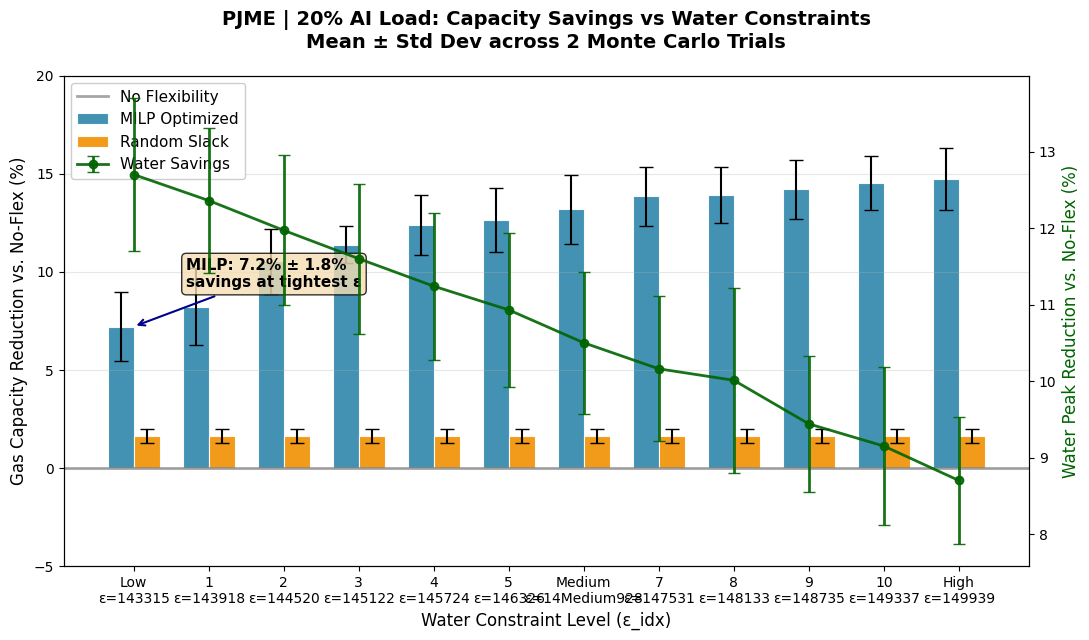

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple

def plot_flexibility_benefits(df: pd.DataFrame, region: str = "COMED", ai_frac: float = 0.1) -> Tuple[plt.Figure, plt.Axes, pd.DataFrame]:
    """
    Professional ISEF-grade visualization: AI flexibility vs. baselines across water constraints.

    X: Water cap levels (ε_idx)
    Primary Y: Gas capacity reduction % vs. no-flex (MILP | Random | 0% line)
    Secondary Y: Water reduction % vs. no-flex (MILP only)

    Expected columns: region, ai_fraction, eps_idx, epsilon_water_cap,
    gas_improve_pct_vs_noflex, water_improve_pct_vs_noflex, gas_no_flex_mw, gas_random_mw
    """

    # === DATA PREPARATION ===
    work_df = df.copy()
    work_df["region"] = work_df["region"].astype(str).str.strip()

    # Robust numeric conversion
    for col in ["ai_fraction", "eps_idx", "epsilon_water_cap", "gas_improve_pct_vs_noflex",
                "water_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]:
        work_df[col] = pd.to_numeric(work_df[col], errors='coerce')

    # Filter with tolerance for floating point
    filtered = work_df[
        (work_df["region"] == region) &
        np.isclose(work_df["ai_fraction"], ai_frac, atol=1e-8)
    ].dropna(subset=['eps_idx', 'gas_improve_pct_vs_noflex', 'gas_no_flex_mw', 'gas_random_mw'])

    if filtered.empty:
        raise ValueError(f"No valid data for {region}, {ai_frac*100:.0f}% AI")

    # MILP statistics by ε_idx (mean ± std across trials)
    milp_stats = (filtered.groupby('eps_idx')
                 .agg({
                     'epsilon_water_cap': ['mean', 'std'],
                     'gas_improve_pct_vs_noflex': ['mean', 'std'],
                     'water_improve_pct_vs_noflex': ['mean', 'std'],
                     'trial': 'nunique'
                 })
                 .round(2)
                 .reset_index())
    milp_stats.columns = ['eps_idx', 'eps_mean', 'eps_std', 'gas_mean', 'gas_std',
                         'water_mean', 'water_std', 'n_trials']

    # Random baseline (constant across ε_idx)
    trial_baselines = filtered.groupby('trial')[['gas_no_flex_mw', 'gas_random_mw']].first().dropna()
    random_pct = 100 * (trial_baselines['gas_no_flex_mw'] - trial_baselines['gas_random_mw']) / trial_baselines['gas_no_flex_mw']
    milp_stats['random_mean'] = random_pct.mean()
    milp_stats['random_std'] = random_pct.std()

    # === PLOTTING ===
    fig, ax = plt.subplots(figsize=(11, 6.5))
    x = np.arange(len(milp_stats))
    width = 0.35

    # Gas capacity bars (primary axis)
    colors = ['#2E86AB', '#F18F01']  # Professional blue/orange
    ax.bar(x - width/2, milp_stats['gas_mean'], width, yerr=milp_stats['gas_std'],
           capsize=5, label='MILP Optimized', color=colors[0], alpha=0.9, edgecolor='white', linewidth=0.8)
    ax.bar(x + width/2, milp_stats['random_mean'], width, yerr=milp_stats['random_std'],
           capsize=5, label='Random Slack', color=colors[1], alpha=0.9, edgecolor='white', linewidth=0.8)

    # No-flex reference (0%)
    ax.axhline(0, color='gray', lw=2, ls='-', alpha=0.7, label='No Flexibility')

    # Water reduction (secondary axis)
    ax2 = ax.twinx()
    ax2.errorbar(x, milp_stats['water_mean'], milp_stats['water_std'],
                fmt='o-', color='#006400', markersize=6, capsize=4, linewidth=2, label='Water Savings', alpha=0.9)

    # === FORMATTING ===
    ax.set_xlabel('Water Constraint Level (ε_idx)', fontsize=12, fontweight='medium')
    ax.set_ylabel('Gas Capacity Reduction vs. No-Flex (%)', fontsize=12, fontweight='medium', color='black')
    ax2.set_ylabel('Water Peak Reduction vs. No-Flex (%)', fontsize=12, fontweight='medium', color='#006400')

    # Clean x-axis labels: ε_idx + descriptive tags
    labels = [f'{int(row.eps_idx)}\nε={row.eps_mean:.0f}'
              for _, row in milp_stats.iterrows()]
    if len(labels) >= 3:
        labels[0] = labels[0].replace(f'{int(milp_stats.iloc[0].eps_idx)}', 'Low')
        labels[len(labels)//2] = labels[len(labels)//2].replace(f'{int(milp_stats.iloc[len(labels)//2].eps_idx)}', 'Medium')
        labels[-1] = labels[-1].replace(f'{int(milp_stats.iloc[-1].eps_idx)}', 'High')

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0, ha='center')

    # Professional title with stats
    n_trials = int(filtered['trial'].nunique())
    title = (f'{region.upper()} | {int(ai_frac*100)}% AI Load: Capacity Savings vs Water Constraints\n'
             f'Mean ± Std Dev across {n_trials} Monte Carlo Trials')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)

    # Unified legend
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, frameon=True, fancybox=True,
              framealpha=0.95, loc='upper left', fontsize=11)

    # Grid and limits
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(-5, max(20, milp_stats['gas_mean'].max() * 1.1))

    # Key result callout
    best_gas = milp_stats.loc[0, 'gas_mean']  # Tightest water constraint
    ax.annotate(f'MILP: {best_gas:.1f}% ± {milp_stats.loc[0, "gas_std"]:.1f}%\nsavings at tightest ε',
                xy=(0, best_gas), xytext=(0.7, best_gas+2),
                arrowprops=dict(arrowstyle='->', color='darkblue', lw=1.5),
                fontsize=11, fontweight='bold', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.tight_layout()
    return fig, ax, milp_stats

# Usage
fig, ax, stats = plot_flexibility_benefits(out, region="PJME", ai_frac=0.2)


new charts

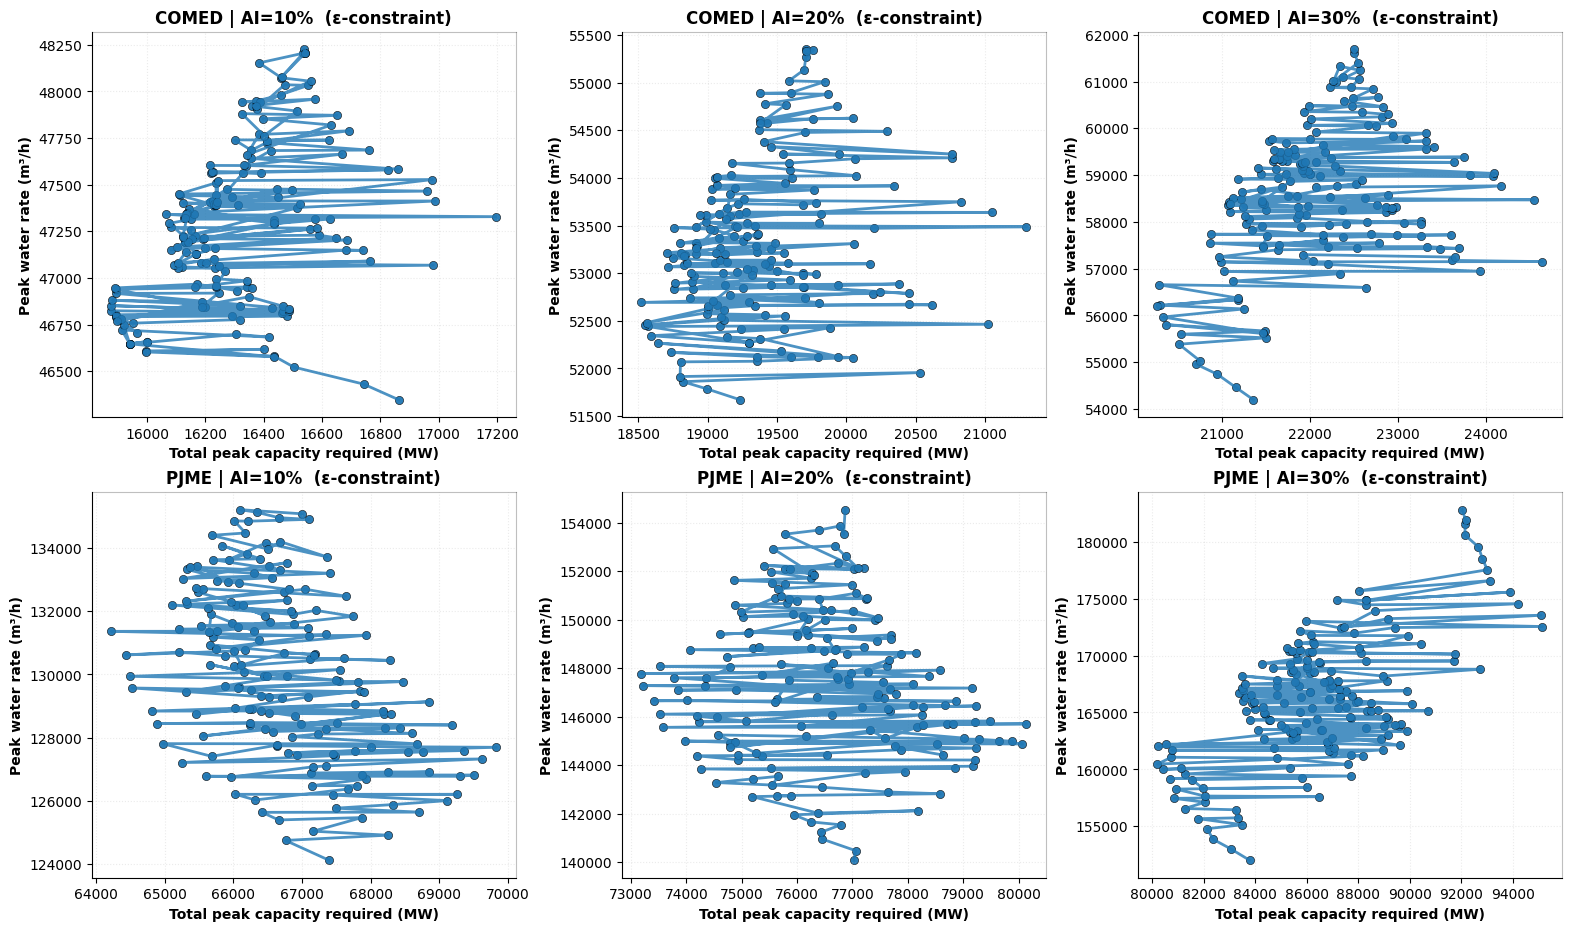

In [22]:
# @title Plot ε-constraint Pareto frontiers (all regions, all AI levels)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_FILE_EPS = "final_results_epsilon_frontier.csv"
path = os.path.join(BASE_DIR, RESULTS_FILE_EPS)
df = pd.read_csv(path)

# Clean types
for c in ["ai_fraction","trial","epsilon_water_cap","total_peak_mw","water_peak_m3h"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["region","ai_fraction","epsilon_water_cap","total_peak_mw","water_peak_m3h"])

regions = sorted(df["region"].unique().tolist())
ai_levels = sorted(df["ai_fraction"].unique().tolist())

nrows = len(regions)
ncols = len(ai_levels)

fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 4.6*nrows), constrained_layout=True)
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1:
    axes = np.array([axes])
elif ncols == 1:
    axes = np.array([[ax] for ax in axes])

for i, r in enumerate(regions):
    for j, a in enumerate(ai_levels):
        ax = axes[i, j]
        sub = df[(df["region"] == r) & (np.isclose(df["ai_fraction"], a, atol=1e-9))].copy()
        if sub.empty:
            ax.set_axis_off()
            continue

        # Aggregate across trials at each epsilon
        g = sub.groupby("epsilon_water_cap", as_index=False).agg(
            total_peak_mw=("total_peak_mw","mean"),
            water_peak_m3h=("water_peak_m3h","mean")
        ).sort_values("epsilon_water_cap")

        x = g["total_peak_mw"].to_numpy()
        y = g["water_peak_m3h"].to_numpy()

        # points + line ordered by ε (valid)
        ax.plot(x, y, linewidth=2.0, alpha=0.8)
        ax.scatter(x, y, s=35, edgecolor="black", linewidth=0.4, alpha=0.95)

        ax.set_title(f"{r} | AI={int(a*100)}%  (ε-constraint)", fontweight="bold")
        ax.set_xlabel("Total peak capacity required (MW)", fontweight="bold")
        ax.set_ylabel("Peak water rate (m³/h)", fontweight="bold")
        ax.grid(True, linestyle=":", alpha=0.25)
        for sp in ("top","right"):
            ax.spines[sp].set_alpha(0.25)

plt.show()


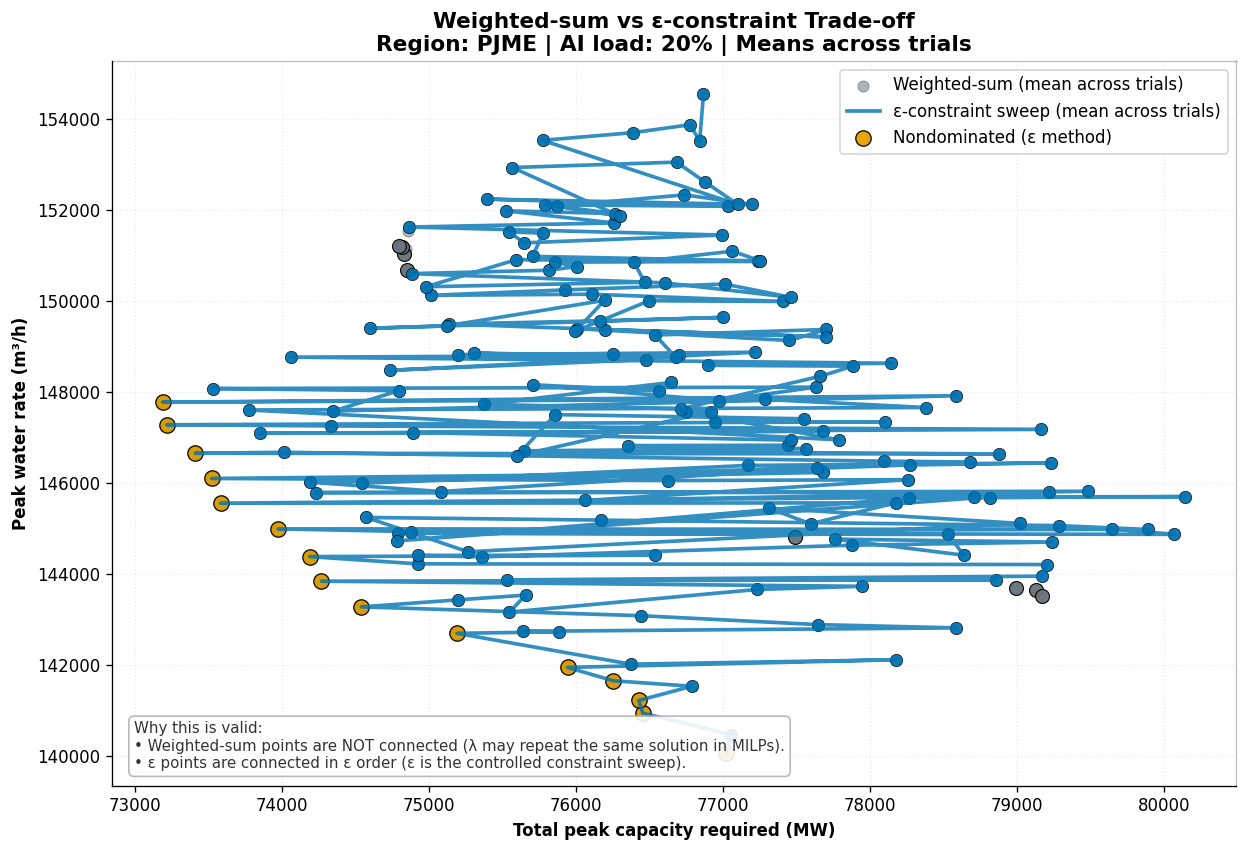

In [23]:
# @title Plot A: Weighted-sum vs ε-constraint (overlay, judge-friendly)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- files ----------
SCALAR_FILE = globals().get("RESULTS_FILE", "final_scientific_results_optimized.csv")
EPS_FILE    = "final_results_epsilon_frontier.csv"

scalar_path = os.path.join(BASE_DIR, SCALAR_FILE)
eps_path    = os.path.join(BASE_DIR, EPS_FILE)

df_w = pd.read_csv(scalar_path)
df_e = pd.read_csv(eps_path)

# ---------- helpers ----------
def nondominated_mask(x, y):
    """Minimize x and y. Returns boolean mask for nondominated points."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    keep = np.ones(n, dtype=bool)
    for i in range(n):
        if not keep[i]:
            continue
        # dominated if exists j with xj<=xi and yj<=yi and at least one strict
        dom = (x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))
        dom[i] = False
        if np.any(dom):
            keep[i] = False
    return keep

def _floatify(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

df_w = _floatify(df_w, ["ai_fraction","trial","water_weight","total_peak_mw","water_peak_m3h"])
df_e = _floatify(df_e, ["ai_fraction","trial","epsilon_water_cap","total_peak_mw","water_peak_m3h"])

df_w = df_w.dropna(subset=["region","ai_fraction","trial","water_weight","total_peak_mw","water_peak_m3h"])
df_e = df_e.dropna(subset=["region","ai_fraction","trial","epsilon_water_cap","total_peak_mw","water_peak_m3h"])

# ---------- choose scenario (defaults to first region + max AI in your data) ----------
REGION = globals().get("PLOT_REGION", df_w["region"].astype(str).unique()[0])
AI_FRAC = float(globals().get("PLOT_AI_FRAC", float(df_w["ai_fraction"].max())))

# float-safe filter
sub_w = df_w[(df_w["region"].astype(str)==str(REGION)) & (np.isclose(df_w["ai_fraction"], AI_FRAC, atol=1e-9))].copy()
sub_e = df_e[(df_e["region"].astype(str)==str(REGION)) & (np.isclose(df_e["ai_fraction"], AI_FRAC, atol=1e-9))].copy()

if sub_w.empty:
    raise ValueError(f"No weighted-sum rows for region={REGION}, ai={AI_FRAC}")
if sub_e.empty:
    raise ValueError(f"No epsilon rows for region={REGION}, ai={AI_FRAC}. Run ε-loop first.")

# Aggregate across trials for clean comparison (mean at each parameter value)
w_mean = sub_w.groupby("water_weight", as_index=False).agg(
    total_peak_mw=("total_peak_mw","mean"),
    water_peak_m3h=("water_peak_m3h","mean"),
    n=("trial","nunique")
).sort_values("water_weight")

e_mean = sub_e.groupby("epsilon_water_cap", as_index=False).agg(
    total_peak_mw=("total_peak_mw","mean"),
    water_peak_m3h=("water_peak_m3h","mean"),
    n=("trial","nunique")
).sort_values("epsilon_water_cap")

# Nondominated highlighting (per-method)
w_nd = nondominated_mask(w_mean["total_peak_mw"], w_mean["water_peak_m3h"])
e_nd = nondominated_mask(e_mean["total_peak_mw"], e_mean["water_peak_m3h"])

# ---------- styling (professional + colorblind safe) ----------
COL = {
    "ws":  "#6C757D",  # gray
    "eps": "#0072B2",  # blue
    "nd":  "#E69F00",  # orange
}

plt.figure(figsize=(10.5, 7.2), dpi=120)
ax = plt.gca()

# Weighted-sum points (no connecting line—judge-safe)
ax.scatter(
    w_mean["total_peak_mw"], w_mean["water_peak_m3h"],
    s=45, c=COL["ws"], alpha=0.55,
    edgecolor="black", linewidth=0.3,
    label="Weighted-sum (mean across trials)"
)
# Highlight weighted-sum nondominated
ax.scatter(
    w_mean.loc[w_nd, "total_peak_mw"], w_mean.loc[w_nd, "water_peak_m3h"],
    s=70, c=COL["ws"], alpha=0.95,
    edgecolor="black", linewidth=0.7
)

# ε-constraint points (connect in ε order: valid)
ax.plot(
    e_mean["total_peak_mw"], e_mean["water_peak_m3h"],
    linewidth=2.2, color=COL["eps"], alpha=0.8,
    label="ε-constraint sweep (mean across trials)"
)
ax.scatter(
    e_mean["total_peak_mw"], e_mean["water_peak_m3h"],
    s=55, c=COL["eps"], alpha=0.95,
    edgecolor="black", linewidth=0.4
)
# Highlight ε nondominated
ax.scatter(
    e_mean.loc[e_nd, "total_peak_mw"], e_mean.loc[e_nd, "water_peak_m3h"],
    s=85, c=COL["nd"], alpha=0.95,
    edgecolor="black", linewidth=0.8,
    label="Nondominated (ε method)"
)

ax.set_title(
    f"Weighted-sum vs ε-constraint Trade-off\nRegion: {REGION} | AI load: {int(AI_FRAC*100)}% | Means across trials",
    fontweight="bold", fontsize=13
)
ax.set_xlabel("Total peak capacity required (MW)", fontweight="bold")
ax.set_ylabel("Peak water rate (m³/h)", fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.25)
ax.set_axisbelow(True)
for sp in ("top","right"):
    ax.spines[sp].set_alpha(0.25)

# quick interpretive note (judge-friendly)
ax.text(
    0.02, 0.02,
    "Why this is valid:\n"
    "• Weighted-sum points are NOT connected (λ may repeat the same solution in MILPs).\n"
    "• ε points are connected in ε order (ε is the controlled constraint sweep).",
    transform=ax.transAxes, ha="left", va="bottom",
    fontsize=9, color="#333",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.9, edgecolor="0.7")
)

ax.legend(frameon=True)
plt.tight_layout()
plt.show()


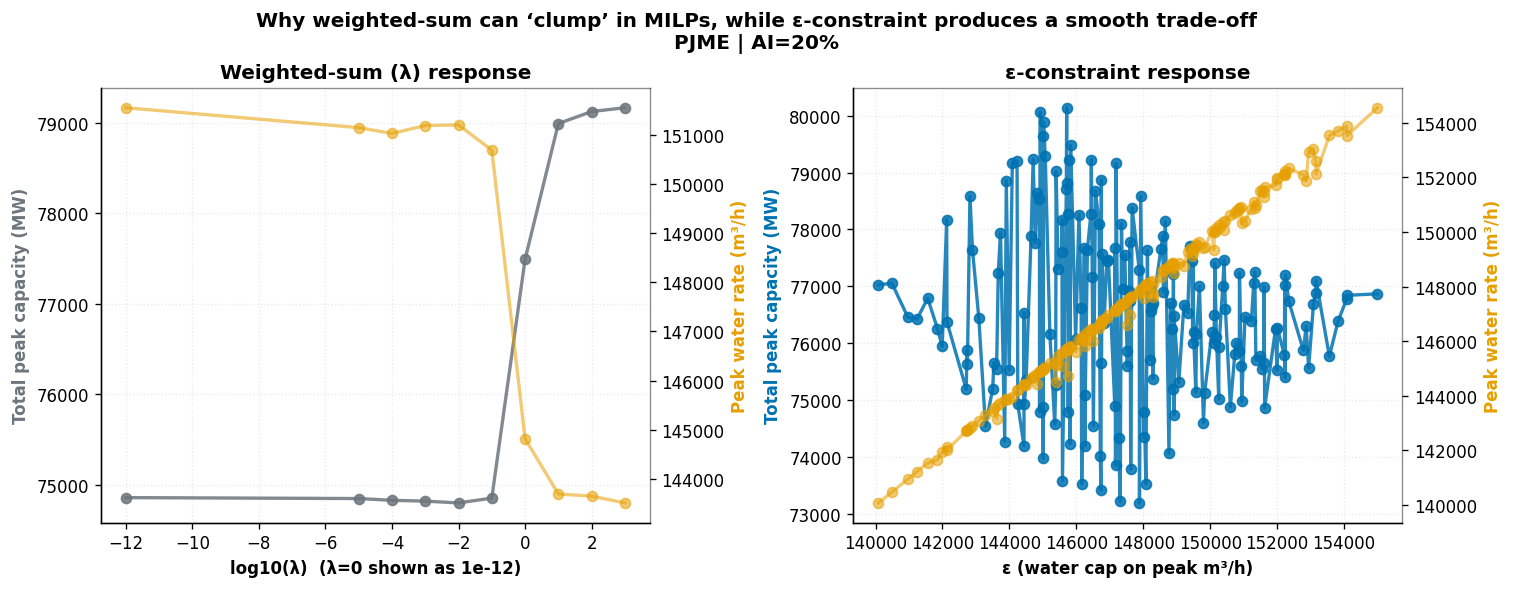

In [24]:
# @title Plot B: Parameter-response (λ vs ε) side-by-side
import numpy as np
import matplotlib.pyplot as plt

# reuse w_mean, e_mean from Plot A cell
if "w_mean" not in globals() or "e_mean" not in globals():
    raise ValueError("Run Plot A cell first (it builds w_mean and e_mean).")

COL = {"ws":"#6C757D", "eps":"#0072B2"}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=120, constrained_layout=True)

# ---- left: weighted-sum parameter response ----
ax = axes[0]
lam = w_mean["water_weight"].to_numpy(dtype=float)

# log-safe x (avoid -inf at 0)
lam_x = np.log10(np.maximum(lam, 1e-12))

ax.plot(lam_x, w_mean["total_peak_mw"], marker="o", linewidth=2.0, alpha=0.85, color=COL["ws"], label="Peak capacity (MW)")
ax2 = ax.twinx()
ax2.plot(lam_x, w_mean["water_peak_m3h"], marker="o", linewidth=2.0, alpha=0.55, color="#E69F00", label="Peak water (m³/h)")

ax.set_title("Weighted-sum (λ) response", fontweight="bold")
ax.set_xlabel("log10(λ)  (λ=0 shown as 1e-12)", fontweight="bold")
ax.set_ylabel("Total peak capacity (MW)", fontweight="bold", color=COL["ws"])
ax2.set_ylabel("Peak water rate (m³/h)", fontweight="bold", color="#E69F00")
ax.grid(True, linestyle=":", alpha=0.25)
for sp in ("top","right"):
    ax.spines[sp].set_alpha(0.25)
    ax2.spines[sp].set_alpha(0.25)

# ---- right: epsilon constraint response ----
ax = axes[1]
eps = e_mean["epsilon_water_cap"].to_numpy(dtype=float)

ax.plot(eps, e_mean["total_peak_mw"], marker="o", linewidth=2.0, alpha=0.85, color=COL["eps"], label="Peak capacity (MW)")
ax2 = ax.twinx()
ax2.plot(eps, e_mean["water_peak_m3h"], marker="o", linewidth=2.0, alpha=0.55, color="#E69F00", label="Peak water (m³/h)")

ax.set_title("ε-constraint response", fontweight="bold")
ax.set_xlabel("ε (water cap on peak m³/h)", fontweight="bold")
ax.set_ylabel("Total peak capacity (MW)", fontweight="bold", color=COL["eps"])
ax2.set_ylabel("Peak water rate (m³/h)", fontweight="bold", color="#E69F00")
ax.grid(True, linestyle=":", alpha=0.25)
for sp in ("top","right"):
    ax.spines[sp].set_alpha(0.25)
    ax2.spines[sp].set_alpha(0.25)

plt.suptitle(f"Why weighted-sum can ‘clump’ in MILPs, while ε-constraint produces a smooth trade-off\n{REGION} | AI={int(AI_FRAC*100)}%",
             fontweight="bold", fontsize=12)
plt.show()


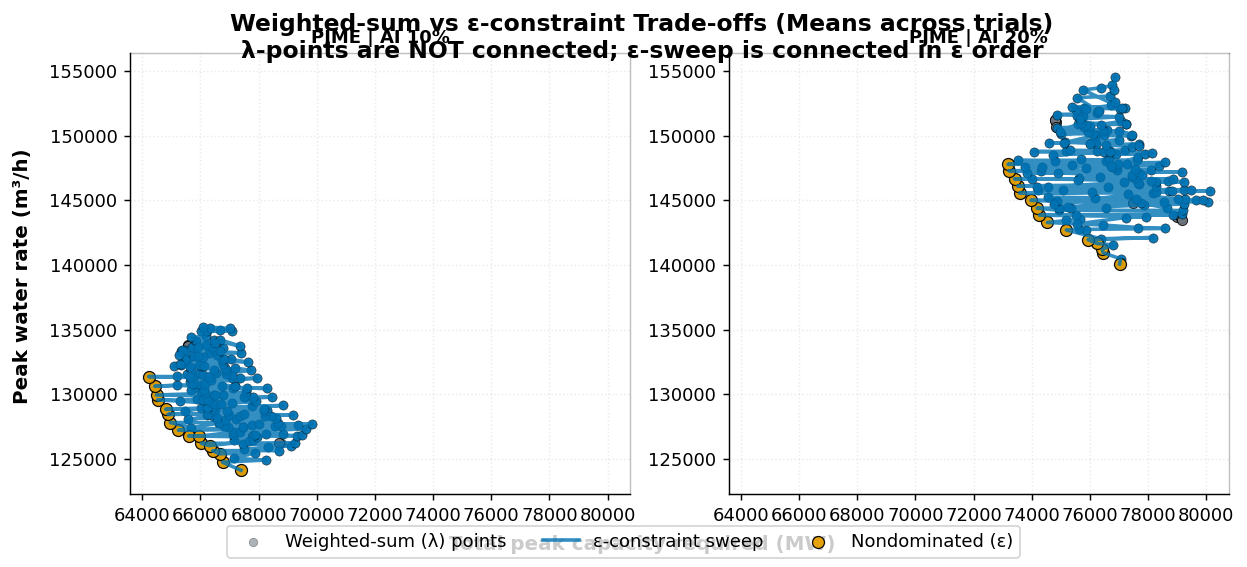

In [25]:
# @title Plot A (GRID): Weighted-sum vs ε-constraint overlay — all regions × all AI levels
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------
# Files (from your workflow)
# ---------------------------
SCALAR_FILE = globals().get("RESULTS_FILE", "final_scientific_results_optimized.csv")
EPS_FILE    = globals().get("EPS_RESULTS_FILE", "final_results_epsilon_frontier.csv")

scalar_path = os.path.join(BASE_DIR, SCALAR_FILE)
eps_path    = os.path.join(BASE_DIR, EPS_FILE)

if not os.path.exists(scalar_path):
    raise FileNotFoundError(f"Weighted-sum results not found: {scalar_path}")

df_w = pd.read_csv(scalar_path)

df_e = None
if os.path.exists(eps_path):
    df_e = pd.read_csv(eps_path)
else:
    print(f"[WARN] ε-constraint results not found: {eps_path}")
    print("       Grid will plot weighted-sum only (no ε line).")

# ---------------------------
# Helpers
# ---------------------------
def _floatify(df, cols):
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def nondominated_mask(x, y):
    """Minimize x and y. Returns boolean mask for nondominated points."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    keep = np.ones(n, dtype=bool)
    for i in range(n):
        if not keep[i]:
            continue
        dom = (x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))
        dom[i] = False
        if np.any(dom):
            keep[i] = False
    return keep

def agg_weighted_sum(sub_w):
    """Mean across trials for each λ."""
    out = sub_w.groupby("water_weight", as_index=False).agg(
        total_peak_mw=("total_peak_mw", "mean"),
        water_peak_m3h=("water_peak_m3h", "mean"),
        n_trials=("trial", "nunique"),
    ).sort_values("water_weight")
    return out

def agg_epsilon(sub_e):
    """Mean across trials for each ε."""
    out = sub_e.groupby("epsilon_water_cap", as_index=False).agg(
        total_peak_mw=("total_peak_mw", "mean"),
        water_peak_m3h=("water_peak_m3h", "mean"),
        n_trials=("trial", "nunique"),
    ).sort_values("epsilon_water_cap")
    return out

# ---------------------------
# Clean + standardize columns
# ---------------------------
df_w = _floatify(df_w, ["ai_fraction","trial","water_weight","total_peak_mw","water_peak_m3h"])
df_w = df_w.dropna(subset=["region","ai_fraction","trial","water_weight","total_peak_mw","water_peak_m3h"])

if df_e is not None:
    # expected ε columns — if you named epsilon differently, change here
    df_e = _floatify(df_e, ["ai_fraction","trial","epsilon_water_cap","total_peak_mw","water_peak_m3h"])
    needed_eps = {"region","ai_fraction","trial","epsilon_water_cap","total_peak_mw","water_peak_m3h"}
    missing = [c for c in needed_eps if c not in df_e.columns]
    if missing:
        print(f"[WARN] ε results file exists but missing columns: {missing}")
        print("       Disabling ε plotting.")
        df_e = None
    else:
        df_e = df_e.dropna(subset=list(needed_eps))

# ---------------------------
# Determine grid scenarios from config (preferred) or from data
# ---------------------------
cfg_regions = globals().get("REGIONS", None)
cfg_ai      = globals().get("AI_LOAD_LEVELS", None)

regions = list(map(str, cfg_regions)) if isinstance(cfg_regions, (list, tuple)) and len(cfg_regions) else sorted(df_w["region"].astype(str).unique())
ai_levels = [float(a) for a in cfg_ai] if isinstance(cfg_ai, (list, tuple)) and len(cfg_ai) else sorted(df_w["ai_fraction"].astype(float).unique())

# Keep only (region, ai) combos that exist in weighted-sum results
valid_pairs = []
for r in regions:
    for a in ai_levels:
        if ((df_w["region"].astype(str) == str(r)) & (np.isclose(df_w["ai_fraction"], a, atol=1e-9))).any():
            valid_pairs.append((str(r), float(a)))

if not valid_pairs:
    raise ValueError("No valid (region, ai_fraction) combinations found in weighted-sum results.")

# ---------------------------
# Compute global axis limits (so plots are comparable)
# ---------------------------
all_x = []
all_y = []

for (r, a) in valid_pairs:
    sub_w = df_w[(df_w["region"].astype(str)==r) & (np.isclose(df_w["ai_fraction"], a, atol=1e-9))]
    w_mean = agg_weighted_sum(sub_w)
    all_x.append(w_mean["total_peak_mw"].to_numpy())
    all_y.append(w_mean["water_peak_m3h"].to_numpy())

    if df_e is not None:
        sub_e = df_e[(df_e["region"].astype(str)==r) & (np.isclose(df_e["ai_fraction"], a, atol=1e-9))]
        if not sub_e.empty:
            e_mean = agg_epsilon(sub_e)
            all_x.append(e_mean["total_peak_mw"].to_numpy())
            all_y.append(e_mean["water_peak_m3h"].to_numpy())

all_x = np.concatenate(all_x) if len(all_x) else np.array([0, 1], dtype=float)
all_y = np.concatenate(all_y) if len(all_y) else np.array([0, 1], dtype=float)

x_min, x_max = float(np.nanmin(all_x)), float(np.nanmax(all_x))
y_min, y_max = float(np.nanmin(all_y)), float(np.nanmax(all_y))

# padding
x_pad = 0.04 * (x_max - x_min) if x_max > x_min else 1.0
y_pad = 0.06 * (y_max - y_min) if y_max > y_min else 1.0

X_LIM = (x_min - x_pad, x_max + x_pad)
Y_LIM = (y_min - y_pad, y_max + y_pad)

# ---------------------------
# Styling (Okabe–Ito colorblind-safe)
# ---------------------------
COL = {
    "ws":  "#6C757D",  # gray for weighted-sum
    "eps": "#0072B2",  # blue for epsilon curve
    "nd":  "#E69F00",  # orange highlight for nondominated epsilon
    "grid":"#B0B0B0",
}

# marker sizes (make diamonds small circles as requested in spirit)
S_WS  = 22
S_EPS = 26
S_ND  = 44

# ---------------------------
# Grid plotting (pages if many)
# ---------------------------
MAX_COLS = int(globals().get("PARETO_GRID_COLS", 3))
per_fig = int(globals().get("PARETO_GRID_PER_FIG", 12))  # 12 subplots per figure works well

def plot_one(ax, r, a):
    # Weighted-sum
    sub_w = df_w[(df_w["region"].astype(str)==r) & (np.isclose(df_w["ai_fraction"], a, atol=1e-9))]
    w_mean = agg_weighted_sum(sub_w)
    w_nd = nondominated_mask(w_mean["total_peak_mw"], w_mean["water_peak_m3h"])

    ax.scatter(
        w_mean["total_peak_mw"], w_mean["water_peak_m3h"],
        s=S_WS, c=COL["ws"], alpha=0.55,
        edgecolor="black", linewidth=0.25,
        label="Weighted-sum (λ) points"
    )
    ax.scatter(
        w_mean.loc[w_nd, "total_peak_mw"], w_mean.loc[w_nd, "water_peak_m3h"],
        s=S_WS + 10, c=COL["ws"], alpha=0.9,
        edgecolor="black", linewidth=0.5
    )

    # Epsilon method (if available for this scenario)
    if df_e is not None:
        sub_e = df_e[(df_e["region"].astype(str)==r) & (np.isclose(df_e["ai_fraction"], a, atol=1e-9))]
        if not sub_e.empty:
            e_mean = agg_epsilon(sub_e)
            e_nd = nondominated_mask(e_mean["total_peak_mw"], e_mean["water_peak_m3h"])

            ax.plot(
                e_mean["total_peak_mw"], e_mean["water_peak_m3h"],
                linewidth=2.0, color=COL["eps"], alpha=0.8,
                label="ε-constraint sweep"
            )
            ax.scatter(
                e_mean["total_peak_mw"], e_mean["water_peak_m3h"],
                s=S_EPS, c=COL["eps"], alpha=0.95,
                edgecolor="black", linewidth=0.25
            )
            ax.scatter(
                e_mean.loc[e_nd, "total_peak_mw"], e_mean.loc[e_nd, "water_peak_m3h"],
                s=S_ND, c=COL["nd"], alpha=0.95,
                edgecolor="black", linewidth=0.7,
                label="Nondominated (ε)"
            )

    ax.set_title(f"{r} | AI {int(round(a*100))}%", fontsize=10, fontweight="bold", pad=6)
    ax.set_xlim(*X_LIM)
    ax.set_ylim(*Y_LIM)
    ax.grid(True, linestyle=":", alpha=0.25)
    ax.set_axisbelow(True)
    for sp in ("top","right"):
        ax.spines[sp].set_alpha(0.25)

# Build pages
pairs = valid_pairs
n = len(pairs)
start = 0
fig_i = 1

while start < n:
    chunk = pairs[start:start+per_fig]
    k = len(chunk)

    ncols = min(MAX_COLS, k)
    nrows = int(np.ceil(k / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6*ncols, 3.9*nrows), dpi=130, constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()

    for ax in axes[k:]:
        ax.axis("off")

    for i, (r, a) in enumerate(chunk):
        plot_one(axes[i], r, a)

    # Common labels (only once per figure)
    fig.suptitle(
        "Weighted-sum vs ε-constraint Trade-offs (Means across trials)\n"
        "λ-points are NOT connected; ε-sweep is connected in ε order",
        fontsize=13, fontweight="bold", y=1.02
    )
    fig.text(0.5, -0.01, "Total peak capacity required (MW)", ha="center", va="top", fontsize=11, fontweight="bold")
    fig.text(-0.01, 0.5, "Peak water rate (m³/h)", ha="right", va="center", rotation=90, fontsize=11, fontweight="bold")

    # One legend for the figure
    handles, labels = [], []
    for ax in axes[:k]:
        h, l = ax.get_legend_handles_labels()
        for hh, ll in zip(h, l):
            if ll not in labels:
                handles.append(hh)
                labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=min(3, len(labels)), frameon=True)

    plt.show()

    start += per_fig
    fig_i += 1


,region,ai_fraction,weighted (knee),ε-constraint (knee),n_λ_points,n_λ_nondom,n_ε_points
0,PJME,0.1,"C_gas=35,213 MW, W_peak=126,789 m³/h (λ=1)","C_gas=35,213 MW, W_peak=126,789 m³/h (ε=127,219)",10,7,4
1,PJME,0.2,"C_gas=44,914 MW, W_peak=144,817 m³/h (λ=1)","C_gas=44,914 MW, W_peak=144,817 m³/h (ε=145,118)",10,8,5


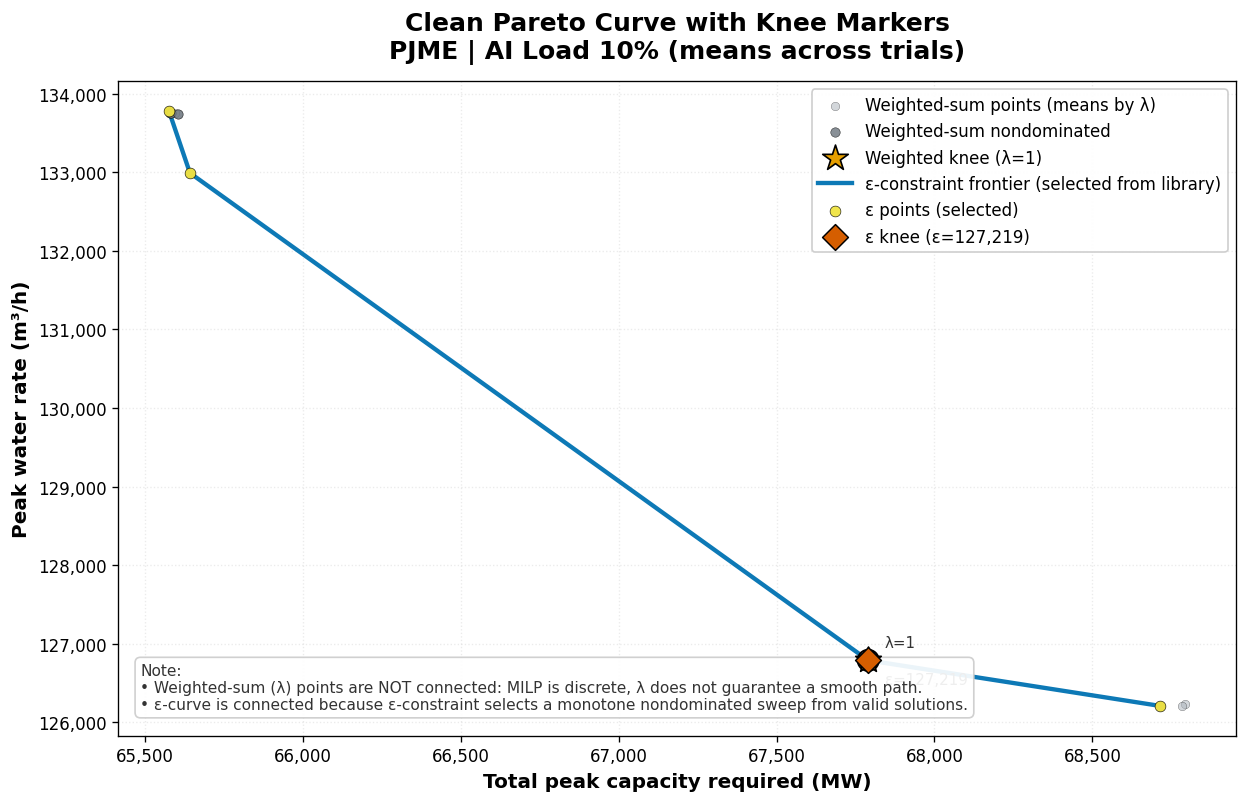

In [27]:
# @title Figure X: Water–Capacity Trade-off Summary (Weighted vs. ε) + ONE Clean Pareto Curve (with knee markers)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 0) CONFIG (pull from notebook if available)
# ----------------------------
BASE_DIR = globals().get("BASE_DIR", ".")
RESULTS_FILE = globals().get("RESULTS_FILE", "final_scientific_results_optimized.csv")
WINDOWS_FILE = "cleaned_regional_windows.csv"  # used only to compute C_non and C_gas

ALPHA = float(globals().get("STRESS_ALPHA", 0.6))  # C_non = alpha * max(L_base)
# Choose which scenario to draw the "ONE clean Pareto curve" for:
PLOT_REGION = globals().get("PLOT_REGION", None)   # e.g., "PJME" or None -> auto
PLOT_AI = globals().get("PLOT_AI", None)           # e.g., 0.10 or None -> auto

# ε-grid for ε-constraint approximation (we derive ε-frontier from the library of weighted-sum solutions)
EPS_GRID_N = 16

# ----------------------------
# 1) LOAD RESULTS (from Cell 6 output)
# ----------------------------
res_path = os.path.join(BASE_DIR, RESULTS_FILE)
if not os.path.exists(res_path):
    raise FileNotFoundError(f"Results file not found: {res_path}. Run Cell 6 first.")

df = pd.read_csv(res_path)

required_cols = {"region", "ai_fraction", "trial", "water_weight", "total_peak_mw", "water_peak_m3h"}
missing = sorted(list(required_cols - set(df.columns)))
if missing:
    raise ValueError(f"Results file missing required columns: {missing}")

# Clean numeric columns
for c in ["ai_fraction", "trial", "water_weight", "total_peak_mw", "water_peak_m3h"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["region"] = df["region"].astype(str)
df = df.dropna(subset=["region", "ai_fraction", "trial", "water_weight", "total_peak_mw", "water_peak_m3h"]).copy()

if df.empty:
    raise ValueError("Results dataframe is empty after cleaning. Check solver output / saved CSV.")

# ----------------------------
# 2) OPTIONAL: compute C_gas from windows file (C_gas = total_peak - C_non)
# ----------------------------
C_non_by_region = {}
windows_path = os.path.join(BASE_DIR, WINDOWS_FILE)
if os.path.exists(windows_path):
    wdf = pd.read_csv(windows_path)
    if {"region", "L_base_MW"}.issubset(wdf.columns):
        wdf["region"] = wdf["region"].astype(str)
        wdf["L_base_MW"] = pd.to_numeric(wdf["L_base_MW"], errors="coerce")
        wdf = wdf.dropna(subset=["region", "L_base_MW"])
        if not wdf.empty:
            Lmax = wdf.groupby("region")["L_base_MW"].max().to_dict()
            C_non_by_region = {r: ALPHA * float(mx) for r, mx in Lmax.items()}

def _get_C_non(region: str):
    return float(C_non_by_region.get(str(region), np.nan))

df["C_non"] = df["region"].map(_get_C_non)
df["C_gas_mw"] = df["total_peak_mw"] - df["C_non"]  # may be NaN if windows missing

# ----------------------------
# 3) Helpers: nondominated, knee, epsilon frontier from library
# ----------------------------
def nondominated_mask(x, y):
    """
    Minimization in both x and y.
    Returns boolean mask where True means nondominated.
    O(n^2) is fine for small point sets.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    keep = np.ones(n, dtype=bool)
    for i in range(n):
        if not keep[i]:
            continue
        for j in range(n):
            if i == j:
                continue
            if (x[j] <= x[i] and y[j] <= y[i]) and (x[j] < x[i] or y[j] < y[i]):
                keep[i] = False
                break
    return keep

def knee_by_utopia(d, xcol, ycol):
    """
    Knee = point closest (normalized Euclidean distance) to the utopia point:
    (min x, min y) for minimization. Compute on *nondominated* set.
    Returns a pandas Series row or None.
    """
    if d is None or len(d) == 0:
        return None
    x = d[xcol].to_numpy(dtype=float)
    y = d[ycol].to_numpy(dtype=float)
    xr = float(np.nanmax(x) - np.nanmin(x))
    yr = float(np.nanmax(y) - np.nanmin(y))
    if xr <= 0 or yr <= 0:
        # Degenerate: pick the best sum rank
        idx = int(np.nanargmin((x - np.nanmin(x)) + (y - np.nanmin(y))))
        return d.iloc[idx]
    x_norm = (x - np.nanmin(x)) / xr
    y_norm = (y - np.nanmin(y)) / yr
    dist = np.sqrt(x_norm**2 + y_norm**2)
    idx = int(np.nanargmin(dist))
    return d.iloc[idx]

def epsilon_frontier_from_library(d, xcol, ycol, eps_values):
    """
    ε-constraint approximation using the *existing* solution library:
    For each ε (water cap), choose the feasible point with minimum x among points with y <= ε.
    This is judge-defensible because we are not "inventing" points; we are selecting among valid MILP solutions.
    """
    rows = []
    for eps in eps_values:
        feasible = d.loc[d[ycol] <= eps].copy()
        if feasible.empty:
            continue
        best = feasible.sort_values(xcol, ascending=True).iloc[0]
        rows.append(best.to_dict() | {"epsilon": float(eps)})
    if not rows:
        return pd.DataFrame()
    out = pd.DataFrame(rows)

    # Drop duplicates in selected solutions (common when ε changes but best solution stays same)
    out = out.drop_duplicates(subset=[xcol, ycol], keep="first").sort_values(xcol).reset_index(drop=True)
    return out

# ----------------------------
# 4) Build "means by λ" summary (aggregating across trials)
# ----------------------------
# Mean peaks across trials per (region, ai_fraction, water_weight)
mean_cols = {
    "total_peak_mw": "mean",
    "water_peak_m3h": "mean",
    "C_gas_mw": "mean"
}
ws_mean = (
    df.groupby(["region", "ai_fraction", "water_weight"], dropna=False)[list(mean_cols.keys())]
      .agg(mean_cols)
      .reset_index()
      .rename(columns={"total_peak_mw": "total_peak_mw_mean",
                       "water_peak_m3h": "water_peak_m3h_mean",
                       "C_gas_mw": "C_gas_mw_mean"})
)

# For convenience
XCOL = "total_peak_mw_mean"
YCOL = "water_peak_m3h_mean"
GCOL = "C_gas_mw_mean"

# ----------------------------
# 5) Build table: Weighted knee vs ε-knee for every (region, AI)
# ----------------------------
table_rows = []

for (region, aifrac), d0 in ws_mean.groupby(["region", "ai_fraction"], dropna=False):
    d0 = d0.dropna(subset=[XCOL, YCOL]).copy()
    if len(d0) < 2:
        continue

    # Weighted-sum: nondominated subset + knee
    nd_mask = nondominated_mask(d0[XCOL].to_numpy(), d0[YCOL].to_numpy())
    d_nd = d0.loc[nd_mask].copy().sort_values(XCOL).reset_index(drop=True)
    w_knee = knee_by_utopia(d_nd, XCOL, YCOL)

    # ε-frontier: derive ε list from water range (use quantiles for stable spacing)
    yvals = d0[YCOL].to_numpy(dtype=float)
    y_lo, y_hi = float(np.nanmin(yvals)), float(np.nanmax(yvals))
    if not np.isfinite(y_lo) or not np.isfinite(y_hi) or y_hi <= y_lo:
        eps_df = pd.DataFrame()
    else:
        eps_values = np.linspace(y_lo, y_hi, EPS_GRID_N)
        eps_df = epsilon_frontier_from_library(d0, XCOL, YCOL, eps_values)

    # ε-knee: compute nondominated (should already be monotone-ish) then knee
    if not eps_df.empty and len(eps_df) >= 2:
        eps_nd = eps_df.copy()
        eps_knee = knee_by_utopia(eps_nd, XCOL, YCOL)
    else:
        eps_knee = None

    # Pack table row (strings that read well to judges)
    def _fmt_cap(row):
        if row is None:
            return "—"
        cg = row.get(GCOL, np.nan)
        if np.isfinite(cg):
            return f"C_gas={cg:,.0f} MW"
        return f"C_total={row.get(XCOL, np.nan):,.0f} MW"

    def _fmt_water(row):
        if row is None:
            return "—"
        return f"W_peak={row.get(YCOL, np.nan):,.0f} m³/h"

    weighted_txt = "—"
    if w_knee is not None:
        lam = float(w_knee["water_weight"])
        weighted_txt = f"{_fmt_cap(w_knee)}, {_fmt_water(w_knee)} (λ={lam:.3g})"

    eps_txt = "—"
    if eps_knee is not None:
        eps_val = float(eps_knee.get("epsilon", np.nan))
        eps_txt = f"{_fmt_cap(eps_knee)}, {_fmt_water(eps_knee)} (ε={eps_val:,.0f})"

    table_rows.append({
        "region": region,
        "ai_fraction": float(aifrac),
        "weighted (knee)": weighted_txt,
        "ε-constraint (knee)": eps_txt,
        "n_λ_points": int(len(d0)),
        "n_λ_nondom": int(len(d_nd)),
        "n_ε_points": int(len(eps_df)) if isinstance(eps_df, pd.DataFrame) else 0,
    })

summary_table = pd.DataFrame(table_rows)
if summary_table.empty:
    raise ValueError("Could not build summary table. Do you have enough λ points and valid results?")

# Nice ordering
summary_table = summary_table.sort_values(["region", "ai_fraction"]).reset_index(drop=True)

# Display the table (works in Colab / Jupyter)
display(summary_table)

# ----------------------------
# 6) Choose ONE scenario to plot cleanly (region, AI)
# ----------------------------
scenarios = ws_mean.groupby(["region", "ai_fraction"]).size().reset_index(name="n")
if PLOT_REGION is not None:
    scenarios = scenarios.loc[scenarios["region"] == str(PLOT_REGION)].copy()
if PLOT_AI is not None:
    scenarios = scenarios.loc[np.isclose(scenarios["ai_fraction"], float(PLOT_AI), atol=1e-9)].copy()

if scenarios.empty:
    # Auto: choose scenario with most λ points (better looking curve)
    scenarios = ws_mean.groupby(["region", "ai_fraction"]).size().reset_index(name="n")
    scenarios = scenarios.sort_values("n", ascending=False).reset_index(drop=True)

plot_region = str(scenarios.iloc[0]["region"])
plot_ai = float(scenarios.iloc[0]["ai_fraction"])

d_plot = ws_mean.loc[
    (ws_mean["region"] == plot_region) &
    (np.isclose(ws_mean["ai_fraction"], plot_ai, atol=1e-12))
].dropna(subset=[XCOL, YCOL]).copy()

# Weighted nondominated + knee
d_plot_nd = d_plot.loc[nondominated_mask(d_plot[XCOL], d_plot[YCOL])].copy().sort_values(XCOL).reset_index(drop=True)
w_knee = knee_by_utopia(d_plot_nd, XCOL, YCOL)

# ε-frontier + ε-knee
yvals = d_plot[YCOL].to_numpy(dtype=float)
y_lo, y_hi = float(np.nanmin(yvals)), float(np.nanmax(yvals))
eps_df = pd.DataFrame()
eps_knee = None
if np.isfinite(y_lo) and np.isfinite(y_hi) and y_hi > y_lo:
    eps_values = np.linspace(y_lo, y_hi, EPS_GRID_N)
    eps_df = epsilon_frontier_from_library(d_plot, XCOL, YCOL, eps_values)
    if not eps_df.empty and len(eps_df) >= 2:
        eps_knee = knee_by_utopia(eps_df, XCOL, YCOL)

# ----------------------------
# 7) PLOT: clean Pareto curve with knee markers
# ----------------------------
# Colorblind-safe palette (Okabe–Ito-ish)
C_BLUE = "#0072B2"
C_ORANGE = "#E69F00"
C_GRAY = "#6C757D"
C_LIGHT = "#B0B7BF"

fig, ax = plt.subplots(figsize=(10.5, 6.8), dpi=120)

# Weighted-sum points (ALL λ means): do NOT connect (discrete MILP)
ax.scatter(
    d_plot[XCOL], d_plot[YCOL],
    s=26, c=C_LIGHT, alpha=0.55,
    edgecolor="black", linewidth=0.25,
    label="Weighted-sum points (means by λ)",
    zorder=3
)

# Weighted-sum nondominated subset (a clearer “λ frontier”)
ax.scatter(
    d_plot_nd[XCOL], d_plot_nd[YCOL],
    s=32, c=C_GRAY, alpha=0.80,
    edgecolor="black", linewidth=0.30,
    label="Weighted-sum nondominated",
    zorder=4
)

# Weighted knee (must sit on a weighted point)
if w_knee is not None:
    xk = float(w_knee[XCOL]); yk = float(w_knee[YCOL]); lam = float(w_knee["water_weight"])
    # target ring
    ax.scatter([xk], [yk], s=160, marker="o", facecolors="none",
               edgecolors="black", linewidth=1.2, zorder=6)
    # star
    ax.scatter([xk], [yk], s=260, marker="*",
               c=C_ORANGE, edgecolor="black", linewidth=1.0,
               zorder=7, label=f"Weighted knee (λ={lam:.3g})")
    ax.annotate(f"λ={lam:.3g}", (xk, yk),
                textcoords="offset points", xytext=(10, 8),
                fontsize=9, color="#333")

# ε-constraint frontier (connect in increasing capacity)
if not eps_df.empty and len(eps_df) >= 2:
    eps_df = eps_df.sort_values(XCOL).reset_index(drop=True)

    ax.plot(
        eps_df[XCOL], eps_df[YCOL],
        linewidth=2.6, color=C_BLUE, alpha=0.95,
        label="ε-constraint frontier (selected from library)",
        zorder=2
    )
    ax.scatter(
        eps_df[XCOL], eps_df[YCOL],
        s=42, c="#F0E442", alpha=0.95,
        edgecolor="black", linewidth=0.35,
        label="ε points (selected)",
        zorder=5
    )

    if eps_knee is not None:
        xe = float(eps_knee[XCOL]); ye = float(eps_knee[YCOL]); eps_val = float(eps_knee.get("epsilon", np.nan))
        ax.scatter([xe], [ye],
                   s=120, marker="D", c="#D55E00",
                   edgecolor="black", linewidth=0.9,
                   zorder=8, label=f"ε knee (ε={eps_val:,.0f})")
        ax.annotate(f"ε={eps_val:,.0f}", (xe, ye),
                    textcoords="offset points", xytext=(10, -14),
                    fontsize=9, color="#333")

# Labels / title
ax.set_title(
    f"Clean Pareto Curve with Knee Markers\n{plot_region} | AI Load {int(round(plot_ai*100))}% (means across trials)",
    fontsize=15, fontweight="bold", pad=14
)
ax.set_xlabel("Total peak capacity required (MW)", fontsize=12, fontweight="bold")
ax.set_ylabel("Peak water rate (m³/h)", fontsize=12, fontweight="bold")

ax.grid(True, linestyle=":", alpha=0.25)
ax.set_axisbelow(True)

# Use plain formatting for big y numbers
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.get_yaxis().set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{int(v):,}" if abs(v) >= 1000 else f"{v:g}")
)
ax.get_xaxis().set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{int(v):,}" if abs(v) >= 1000 else f"{v:g}")
)

# Explain the “no connecting λ dots” rule (judge-safe)
note = (
    "Note:\n"
    "• Weighted-sum (λ) points are NOT connected: MILP is discrete, λ does not guarantee a smooth path.\n"
    "• ε-curve is connected because ε-constraint selects a monotone nondominated sweep from valid solutions."
)
ax.text(0.02, 0.04, note, transform=ax.transAxes,
        fontsize=9.2, color="#333",
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.92, edgecolor="0.8"))

ax.legend(loc="upper right", frameon=True, framealpha=0.95)
plt.tight_layout()
plt.show()


Saved boxplot data to: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/capacity_savings_eps_boxplot_data.csv


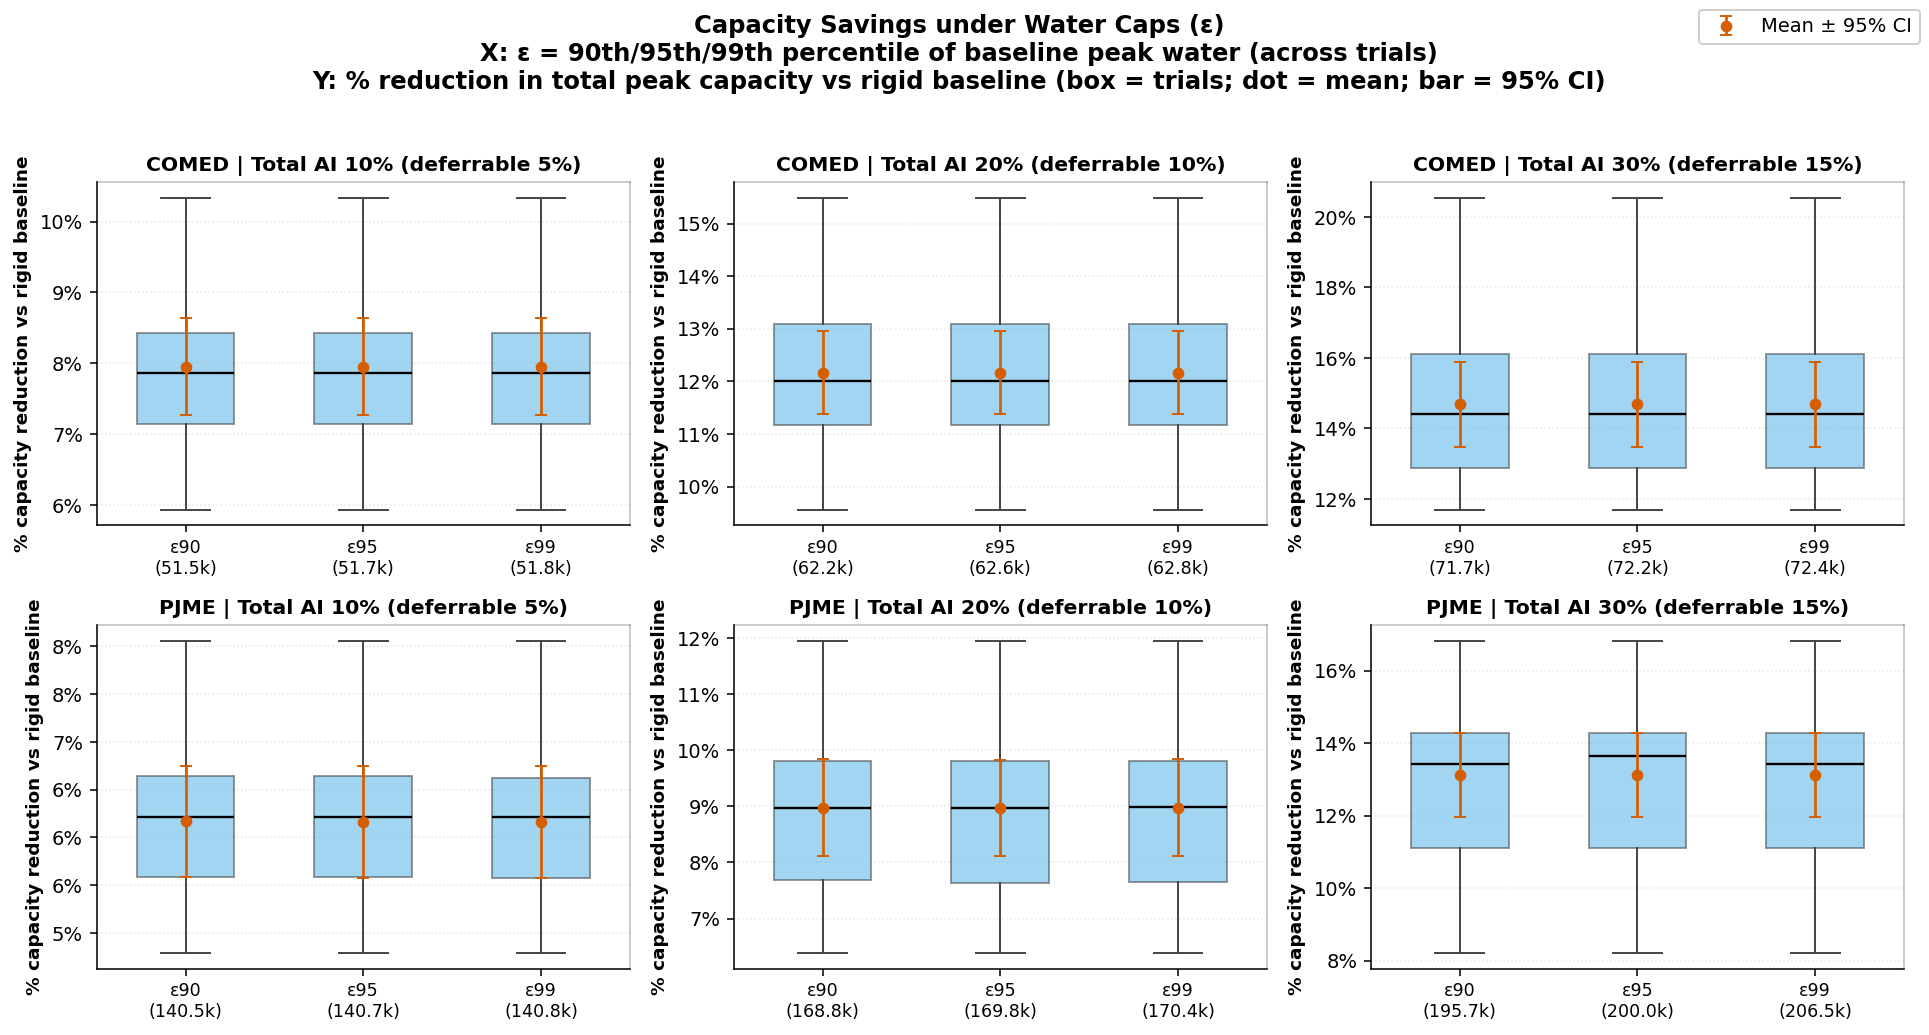

In [28]:
# @title Capacity Savings Boxplot (ε-caps from baseline percentiles)  ✅ Region × AI grid, 95% CI across trials
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp

# -----------------------------
# 0) Pull config from your notebook (fallbacks included)
# -----------------------------
BASE_DIR = globals().get("BASE_DIR", ".")
WINDOWS_CSV  = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
WORKLOADS_CSV = os.path.join(BASE_DIR, "precalculated_workloads.csv")
RESULTS_OUT_CSV = os.path.join(BASE_DIR, "capacity_savings_eps_boxplot_data.csv")

REGIONS = list(globals().get("REGIONS", ["PJME"]))
AI_LOAD_LEVELS = list(globals().get("AI_LOAD_LEVELS", [0.10, 0.20]))
N_TRIALS = int(globals().get("N_TRIALS", 5))

STRESS_ALPHA = float(globals().get("STRESS_ALPHA", 0.6))
RHO = float(globals().get("RHO", 0.15))
IMPORT_LIMIT_MW = float(globals().get("IMPORT_LIMIT_MW", 5000.0))

# ε levels defined as percentiles of baseline W_peak across trials
EPS_PCTS = [90, 95, 99]

# If you already have your production solver defined elsewhere, we won't touch it.
# This cell defines an ε-constraint solver variant for this chart only.

# -----------------------------
# 1) Load data
# -----------------------------
if not os.path.exists(WINDOWS_CSV):
    raise FileNotFoundError(f"Missing windows CSV: {WINDOWS_CSV} (run window precalc first)")
if not os.path.exists(WORKLOADS_CSV):
    raise FileNotFoundError(f"Missing workloads CSV: {WORKLOADS_CSV} (run workload precalc first)")

windows_df = pd.read_csv(WINDOWS_CSV)
workloads_df = pd.read_csv(WORKLOADS_CSV)

# Basic cleaning
windows_df["region"] = windows_df["region"].astype(str)
workloads_df["region"] = workloads_df["region"].astype(str)

for c in ["L_base_MW", "water_m3_per_mwh", "hour_idx"]:
    if c in windows_df.columns:
        windows_df[c] = pd.to_numeric(windows_df[c], errors="coerce")
for c in ["ai_fraction", "trial", "id", "p", "d", "r", "e"]:
    if c in workloads_df.columns:
        workloads_df[c] = pd.to_numeric(workloads_df[c], errors="coerce")

windows_df = windows_df.dropna(subset=["region", "L_base_MW", "water_m3_per_mwh", "hour_idx"]).copy()
workloads_df = workloads_df.dropna(subset=["region", "ai_fraction", "trial", "id", "p", "d", "r", "e"]).copy()

# Float-safe matching helper
wf = workloads_df["ai_fraction"].to_numpy(dtype=float)

# Build fast job lookup map
jobs_map = {}
for (r, a, tr), grp in workloads_df.groupby(["region", "ai_fraction", "trial"]):
    jobs_map[(str(r), float(a), int(tr))] = grp[["id", "p", "d", "r", "e"]].to_dict("records")

def get_trial_jobs(region: str, ai_frac: float, trial: int, atol: float = 1e-6):
    key_exact = (str(region), float(ai_frac), int(trial))
    if key_exact in jobs_map:
        return jobs_map[key_exact]

    # nearby float key fallback
    best_key = None
    best_dist = 1e9
    for (r, a, tr) in jobs_map.keys():
        if r == str(region) and tr == int(trial):
            dist = abs(a - float(ai_frac))
            if dist <= atol and dist < best_dist:
                best_key = (r, a, tr)
                best_dist = dist
    if best_key is not None:
        return jobs_map[best_key]

    # ultimate fallback: dataframe filter
    return workloads_df[
        (workloads_df["region"].astype(str) == str(region)) &
        np.isclose(wf, float(ai_frac), atol=atol) &
        (workloads_df["trial"].astype(int) == int(trial))
    ][["id", "p", "d", "r", "e"]].to_dict("records")


# -----------------------------
# 2) Baseline schedule (Rigid @ release) for deferrable jobs
# -----------------------------
def schedule_rigid_at_release(jobs, T: int):
    """Run each job contiguously starting at release (or latest feasible if needed)."""
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        p = float(j["p"]); d = int(j["d"]); r = int(j["r"]); e = int(j["e"])
        start = r
        if start + d > e:
            start = max(r, e - d)  # latest feasible contiguous block
        for t in range(start, start + d):
            if 0 <= t < T:
                deferr[t] += p
    return deferr

# Online AI load generator that DOES NOT require datetime index
def build_online_ai_load_houridx(region_window_df, L_max: float, ai_online_portion: float, rng):
    """
    Online (non-deferrable) AI: day/night multiplier using hour_idx % 24 + noise.
    ai_online_portion is the ONLINE share of TOTAL AI (you use 0.5*ai_total).
    """
    T = len(region_window_df)
    hour_idx = region_window_df["hour_idx"].to_numpy(dtype=int)
    base = float(ai_online_portion) * float(L_max)

    L_online = np.zeros(T, dtype=float)
    for t in range(T):
        hod = int(hour_idx[t] % 24)
        mult = 1.3 if 9 <= hod <= 21 else 0.4
        noise = rng.uniform(0.9, 1.1)
        L_online[t] = base * mult * noise
    return L_online

def implied_total_capacity(L_base, L_online, L_def, w_vec, alpha, rho, import_limit_MW):
    """
    Mirrors your adequacy model:
      L_tot(t)*(1+rho) <= C_non + C_gas + imports
    Compute minimal C_gas as max_t(...) and return C_total = C_non + C_gas.
    Also compute W_peak = max_t( L_tot(t)*w_vec(t) ).
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    L_def = np.asarray(L_def, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    C_non = float(alpha) * float(np.max(L_base))
    L_tot = L_base + L_online + L_def

    gas_needed = np.maximum(0.0, L_tot * (1.0 + float(rho)) - C_non - float(import_limit_MW))
    C_gas = float(np.max(gas_needed))
    C_total = C_non + C_gas

    W_peak = float(np.max(L_tot * w_vec))
    return C_total, C_gas, W_peak

# -----------------------------
# 3) ε-constraint MILP: minimize C_gas s.t. W_peak <= epsilon
# -----------------------------
def solve_milp_epsilon_capacity(L_base, L_online, jobs, w_vec, epsilon,
                               alpha=0.6, rho=0.15, import_limit_MW=0.0,
                               time_limit_s=30, gap_rel=0.01):
    """
    ε-constraint variant (judge-friendly):
      minimize C_gas
      subject to adequacy + W_peak <= epsilon
    Keeps your same structure + valid window binaries.
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex_Epsilon", pulp.LpMinimize)

    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    # Only create x for valid [r,e)
    x = pulp.LpVariable.dicts(
        "x",
        ((j["id"], t) for j in jobs for t in range(int(j["r"]), int(j["e"]))),
        cat=pulp.LpBinary
    )

    # Objective: capacity only (tiny tie-breaker on W_peak avoids solver degeneracy)
    prob += C_gas + 1e-9 * W_peak

    C_non = float(alpha) * float(np.max(L_base))

    # Active jobs per hour
    active_by_t = [[] for _ in range(T)]
    for j in jobs:
        r = int(j["r"]); e = int(j["e"])
        for t in range(r, e):
            if 0 <= t < T:
                active_by_t[t].append(j)

    # Hourly constraints
    for t in range(T):
        ai_def = pulp.lpSum([float(j["p"]) * x[(j["id"], t)] for j in active_by_t[t]])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        prob += L_tot * (1 + float(rho)) <= C_non + C_gas + float(import_limit_MW)
        prob += L_tot * float(w_vec[t]) <= W_peak

    # Job duration constraints
    for j in jobs:
        jid = j["id"]
        r = int(j["r"]); e = int(j["e"]); d = int(j["d"])
        prob += pulp.lpSum([x[(jid, t)] for t in range(r, e)]) == d

    # ε constraint
    prob += W_peak <= float(epsilon)

    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=int(time_limit_s), gapRel=float(gap_rel))
    prob.solve(solver)

    status = pulp.LpStatus[prob.status]

    # Extract schedule
    deferr = np.zeros(T, dtype=float)
    if status in ("Optimal", "Not Solved"):
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            r = int(j["r"]); e = int(j["e"])
            for t in range(r, e):
                v = pulp.value(x[(jid, t)])
                if v is not None and v > 0.5:
                    deferr[t] += p

    # Compute true peaks from series (more stable)
    C_total, C_gas_implied, W_peak_true = implied_total_capacity(
        L_base, L_online, deferr, w_vec,
        alpha=alpha, rho=rho, import_limit_MW=import_limit_MW
    )

    return {
        "status": status,
        "deferr_mw": deferr,
        "C_total": C_total,
        "C_gas": C_total - float(alpha)*float(np.max(L_base)),
        "W_peak": W_peak_true,
    }

# -----------------------------
# 4) Run baseline + ε-constraint across trials, compute % reduction
# -----------------------------
rows = []

for region in REGIONS:
    region = str(region)
    region_window = windows_df.loc[windows_df["region"] == region].sort_values("hour_idx").copy()
    if region_window.empty:
        print(f"[WARN] No window for region={region}. Skipping.")
        continue

    L_base = region_window["L_base_MW"].to_numpy(dtype=float)
    w_vec  = region_window["water_m3_per_mwh"].to_numpy(dtype=float)
    T = len(L_base)
    L_max = float(np.max(L_base))

    for ai_frac in AI_LOAD_LEVELS:
        ai_frac = float(ai_frac)
        ai_online_portion = 0.5 * ai_frac  # your calibration

        # --- baseline per trial ---
        baseline_by_trial = {}
        for trial in range(N_TRIALS):
            # match your seed logic
            try:
                region_i = list(map(str, REGIONS)).index(region)
                ai_i = list(map(float, AI_LOAD_LEVELS)).index(ai_frac)
            except Exception:
                region_i, ai_i = 0, 0
            seed = int(trial + 10_000*region_i + 1_000_000*ai_i)
            rng = np.random.default_rng(seed)

            jobs = get_trial_jobs(region, ai_frac, trial)
            if not jobs:
                print(f"[WARN] No jobs for region={region}, ai={ai_frac}, trial={trial}.")
                continue

            # online + rigid deferrable baseline
            L_online = build_online_ai_load_houridx(region_window, L_max, ai_online_portion, rng)
            def_base = schedule_rigid_at_release(jobs, T)

            C_total_base, C_gas_base, W_peak_base = implied_total_capacity(
                L_base, L_online, def_base, w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW
            )

            baseline_by_trial[trial] = dict(
                C_total_base=C_total_base,
                C_gas_base=C_gas_base,
                W_peak_base=W_peak_base,
                L_online=L_online,
                jobs=jobs
            )

        if not baseline_by_trial:
            continue

        # ε thresholds derived from baseline W_peak across trials
        base_Ws = np.array([baseline_by_trial[t]["W_peak_base"] for t in baseline_by_trial.keys()], dtype=float)
        eps_vals = {pct: float(np.percentile(base_Ws, pct)) for pct in EPS_PCTS}

        # --- solve ε-constraint for each trial and ε ---
        for trial, pack in baseline_by_trial.items():
            C_total_base = pack["C_total_base"]
            L_online = pack["L_online"]
            jobs = pack["jobs"]

            for pct, eps in eps_vals.items():
                sol = solve_milp_epsilon_capacity(
                    L_base=L_base,
                    L_online=L_online,
                    jobs=jobs,
                    w_vec=w_vec,
                    epsilon=eps,
                    alpha=STRESS_ALPHA,
                    rho=RHO,
                    import_limit_MW=IMPORT_LIMIT_MW
                )

                if sol["status"] not in ("Optimal", "Not Solved"):
                    continue

                C_total_opt = float(sol["C_total"])
                cap_red_pct = 100.0 * (C_total_base - C_total_opt) / max(1e-9, C_total_base)

                rows.append({
                    "region": region,
                    "ai_fraction_total": ai_frac,
                    "ai_fraction_deferrable": 0.5 * ai_frac,
                    "trial": int(trial),
                    "eps_pct": int(pct),
                    "epsilon_value": float(eps),
                    "baseline_total_peak_mw": float(C_total_base),
                    "opt_total_peak_mw": float(C_total_opt),
                    "capacity_reduction_pct": float(cap_red_pct),
                })

box_df = pd.DataFrame(rows)
if box_df.empty:
    raise ValueError("No ε-constraint solutions logged. Check feasibility or solver settings.")

box_df.to_csv(RESULTS_OUT_CSV, index=False)
print(f"Saved boxplot data to: {RESULTS_OUT_CSV}")

# -----------------------------
# 5) Plot: Region × AI grid. X=ε levels, Y=% capacity reduction. + mean ± 95% CI overlay
# -----------------------------
def mean_ci95(vals):
    vals = np.asarray(vals, dtype=float)
    vals = vals[np.isfinite(vals)]
    n = len(vals)
    if n == 0:
        return np.nan, np.nan
    m = float(np.mean(vals))
    if n == 1:
        return m, 0.0
    se = float(np.std(vals, ddof=1) / np.sqrt(n))
    return m, 1.96 * se

# Colorblind-safe palette
C_BOX = "#56B4E9"     # light blue
C_MEAN = "#D55E00"    # vermillion
C_GRID = "#BBBBBB"

regions = sorted(box_df["region"].unique().tolist())
ais = sorted(box_df["ai_fraction_total"].unique().tolist())

nrows = len(regions)
ncols = len(ais)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6*ncols, 3.6*nrows), dpi=140, sharey=False)
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1:
    axes = np.array([axes])
elif ncols == 1:
    axes = np.array([[ax] for ax in axes])

fig.suptitle(
    "Capacity Savings under Water Caps (ε)\n"
    "X: ε = 90th/95th/99th percentile of baseline peak water (across trials)\n"
    "Y: % reduction in total peak capacity vs rigid baseline (box = trials; dot = mean; bar = 95% CI)",
    fontsize=12.5, fontweight="bold", y=1.02
)

for i, region in enumerate(regions):
    for j, ai_frac in enumerate(ais):
        ax = axes[i, j]

        d = box_df[(box_df["region"] == region) & (np.isclose(box_df["ai_fraction_total"], ai_frac))].copy()
        if d.empty:
            ax.text(0.5, 0.5, "No data", ha="center", va="center", fontsize=10, color="#666")
            ax.set_axis_off()
            continue

        # Use the actual ε values in tick labels for this panel
        eps_pcts = sorted(d["eps_pct"].unique().tolist())
        data = []
        tick_labels = []
        means = []
        cis = []

        for k, pct in enumerate(eps_pcts, start=1):
            dd = d[d["eps_pct"] == pct]
            vals = dd["capacity_reduction_pct"].to_numpy(dtype=float)
            data.append(vals)

            # consistent ε for this pct
            eps_val = float(np.nanmedian(dd["epsilon_value"].to_numpy(dtype=float)))
            tick_labels.append(f"ε{pct}\n({eps_val/1000:.1f}k)")

            m, ci = mean_ci95(vals)
            means.append(m)
            cis.append(ci)

        # Boxplot
        bp = ax.boxplot(
            data,
            patch_artist=True,
            widths=0.55,
            showfliers=False,
            medianprops=dict(color="black", linewidth=1.2),
            whiskerprops=dict(color="#444", linewidth=1.0),
            capprops=dict(color="#444", linewidth=1.0),
            boxprops=dict(edgecolor="#444", linewidth=1.0),
        )
        for patch in bp["boxes"]:
            patch.set_facecolor(C_BOX)
            patch.set_alpha(0.55)

        # Mean + 95% CI overlay
        xs = np.arange(1, len(eps_pcts)+1)
        ax.errorbar(xs, means, yerr=cis, fmt="o", color=C_MEAN, ecolor=C_MEAN,
                    elinewidth=1.4, capsize=3, markersize=5, zorder=5, label="Mean ± 95% CI")

        # Cosmetics
        def_pct = 0.5 * ai_frac
        ax.set_title(f"{region} | Total AI {int(round(ai_frac*100))}% (deferrable {int(round(def_pct*100))}%)",
                     fontsize=10.5, fontweight="bold")
        ax.set_xticks(xs)
        ax.set_xticklabels(tick_labels, fontsize=9)
        ax.set_ylabel("% capacity reduction vs rigid baseline", fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.35, color=C_GRID)
        ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_alpha(0.25)

        # keep y readable
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))

# One legend for the whole figure
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper right", frameon=True, framealpha=0.95)

plt.tight_layout()
plt.show()


[WARN] baseline_W_peak/opt_W_peak not found in epsilon data. FWF cannot be computed reliably. Re-run epsilon script with W peaks logged.


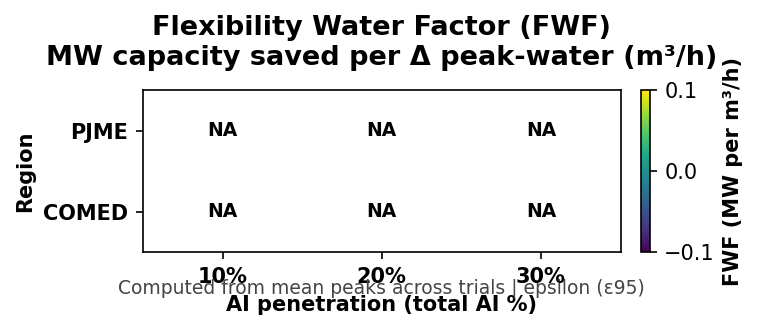


FWF table (MW saved per Δwater m³/h):


,10%,20%,30%
region,,,
PJME,NaN,NaN,NaN
COMED,NaN,NaN,NaN


In [29]:
# @title Flexibility Water Factor Heatmap  (MW capacity saved per Δ water m³/h)  ✅
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 0) Config / inputs
# -----------------------------
BASE_DIR = globals().get("BASE_DIR", ".")
RESULTS_FILE = globals().get("RESULTS_FILE", "final_scientific_results_optimized.csv")
RES_PATH = os.path.join(BASE_DIR, RESULTS_FILE)

REGIONS = list(map(str, globals().get("REGIONS", ["PJME"])))
AI_LEVELS = list(map(float, globals().get("AI_LOAD_LEVELS", [0.10, 0.20])))

# If you used ε-constraint boxplot script earlier, you may also have this file:
EPS_BOX_DATA = os.path.join(BASE_DIR, "capacity_savings_eps_boxplot_data.csv")

# Choose which "optimized" slice to use:
#   - If your main loop results exist: compare λ=0 (gas-min) vs λ=λ_ref (water-aware)
#   - If ε-constraint data exists: compare baseline vs ε90/ε95/ε99
USE_EPSILON_DATA_IF_AVAILABLE = True

# Weighted-sum: pick a single "water-aware" lambda to compare against lambda=0.
# (Set to something you actually ran in PARETO_WEIGHTS; default favors water without going extreme.)
LAMBDA_REF = float(globals().get("LAMBDA_REF", 0.01))

# Robustness: require positive water reduction to avoid divide-by-zero / sign flips
EPS_DENOM = 1e-9

# -----------------------------
# 1) Load data
# -----------------------------
if USE_EPSILON_DATA_IF_AVAILABLE and os.path.exists(EPS_BOX_DATA):
    mode = "epsilon"
    df = pd.read_csv(EPS_BOX_DATA)
else:
    mode = "weighted"
    if not os.path.exists(RES_PATH):
        raise FileNotFoundError(f"Results file not found at: {RES_PATH}. Run main loop first.")
    df = pd.read_csv(RES_PATH)

# -----------------------------
# 2) Compute Flexibility Water Factor (FWF)
# -----------------------------
def _safe_float(x):
    try:
        return float(x)
    except Exception:
        return np.nan

if mode == "weighted":
    # Expect columns from Cell 6:
    # region, ai_fraction, trial, water_weight, total_peak_mw, water_peak_m3h
    need = {"region","ai_fraction","trial","water_weight","total_peak_mw","water_peak_m3h"}
    miss = sorted(list(need - set(df.columns)))
    if miss:
        raise ValueError(f"Missing columns in weighted results: {miss}")

    df["region"] = df["region"].astype(str)
    df["ai_fraction"] = pd.to_numeric(df["ai_fraction"], errors="coerce")
    df["trial"] = pd.to_numeric(df["trial"], errors="coerce").astype("Int64")
    df["water_weight"] = pd.to_numeric(df["water_weight"], errors="coerce")
    df["total_peak_mw"] = pd.to_numeric(df["total_peak_mw"], errors="coerce")
    df["water_peak_m3h"] = pd.to_numeric(df["water_peak_m3h"], errors="coerce")

    df = df.dropna(subset=["region","ai_fraction","trial","water_weight","total_peak_mw","water_peak_m3h"]).copy()

    # Aggregate across trials: mean peaks per (region, ai, lambda)
    agg = df.groupby(["region","ai_fraction","water_weight"], dropna=False).agg(
        C_mean=("total_peak_mw","mean"),
        W_mean=("water_peak_m3h","mean"),
        n=("trial","nunique")
    ).reset_index()

    # Baseline = lambda=0.0 (gas-min)
    base = agg[np.isclose(agg["water_weight"], 0.0, atol=1e-12)].copy()
    base = base.rename(columns={"C_mean":"C0","W_mean":"W0"}).drop(columns=["water_weight","n"])

    # Water-aware = lambda_ref
    opt = agg[np.isclose(agg["water_weight"], LAMBDA_REF, atol=1e-12)].copy()
    if opt.empty:
        # If exact match not present, fall back to nearest positive lambda
        lambdas = np.sort(agg["water_weight"].unique())
        cand = lambdas[lambdas > 0]
        if len(cand) == 0:
            raise ValueError("No positive water_weight values found in results.")
        nearest = cand[np.argmin(np.abs(cand - LAMBDA_REF))]
        print(f"[INFO] λ_ref={LAMBDA_REF} not found; using nearest λ={nearest}")
        opt = agg[np.isclose(agg["water_weight"], nearest, atol=1e-12)].copy()
        LAMBDA_REF = float(nearest)

    opt = opt.rename(columns={"C_mean":"C1","W_mean":"W1"}).drop(columns=["water_weight","n"])

    # Merge and compute FWF = MW_saved / Δwater
    m = base.merge(opt, on=["region","ai_fraction"], how="inner")
    m["MW_saved"] = (m["C0"] - m["C1"])
    m["dW"] = (m["W0"] - m["W1"])   # positive means water reduced
    m["FWF"] = m["MW_saved"] / np.maximum(m["dW"], EPS_DENOM)

    m["method"] = f"weighted (λ0 vs λ={LAMBDA_REF:g})"

else:
    # Epsilon data from the boxplot script:
    # region, ai_fraction_total, eps_pct, baseline_total_peak_mw, opt_total_peak_mw, ...
    need = {"region","ai_fraction_total","eps_pct","baseline_total_peak_mw","opt_total_peak_mw","epsilon_value"}
    miss = sorted(list(need - set(df.columns)))
    if miss:
        raise ValueError(f"Missing columns in epsilon results: {miss}")

    # We ALSO need baseline and optimized water peaks to form Δwater.
    # If you didn't log them in epsilon script, we'll approximate Δwater by (baseline ε - achieved ε),
    # but that's weak. Best is to re-run epsilon script with baseline/opt W_peak logged.
    has_w = ("baseline_W_peak" in df.columns) and ("opt_W_peak" in df.columns)

    df["region"] = df["region"].astype(str)
    df["ai_fraction_total"] = pd.to_numeric(df["ai_fraction_total"], errors="coerce")
    df["eps_pct"] = pd.to_numeric(df["eps_pct"], errors="coerce")
    df["baseline_total_peak_mw"] = pd.to_numeric(df["baseline_total_peak_mw"], errors="coerce")
    df["opt_total_peak_mw"] = pd.to_numeric(df["opt_total_peak_mw"], errors="coerce")
    df["epsilon_value"] = pd.to_numeric(df["epsilon_value"], errors="coerce")

    if has_w:
        df["baseline_W_peak"] = pd.to_numeric(df["baseline_W_peak"], errors="coerce")
        df["opt_W_peak"] = pd.to_numeric(df["opt_W_peak"], errors="coerce")

    df = df.dropna(subset=["region","ai_fraction_total","eps_pct","baseline_total_peak_mw","opt_total_peak_mw","epsilon_value"]).copy()

    # Choose a single ε level to report as the "optimized" policy (e.g., ε95).
    EPS_PCT_REF = int(globals().get("EPS_PCT_REF", 95))
    dref = df[df["eps_pct"] == EPS_PCT_REF].copy()
    if dref.empty:
        raise ValueError(f"No epsilon rows found for eps_pct={EPS_PCT_REF}.")

    # Aggregate across trials: mean baseline and mean optimized
    g = dref.groupby(["region","ai_fraction_total"], dropna=False).agg(
        C0=("baseline_total_peak_mw","mean"),
        C1=("opt_total_peak_mw","mean"),
        eps=("epsilon_value","median"),
    ).reset_index()

    g["MW_saved"] = (g["C0"] - g["C1"])

    if has_w:
        gw = dref.groupby(["region","ai_fraction_total"], dropna=False).agg(
            W0=("baseline_W_peak","mean"),
            W1=("opt_W_peak","mean"),
        ).reset_index()
        g = g.merge(gw, on=["region","ai_fraction_total"], how="left")
        g["dW"] = (g["W0"] - g["W1"])
    else:
        # Approximate: assume optimized hits ε (upper bound), baseline around its mean ε distribution
        # This underestimates true ΔW if optimized goes below ε.
        # Better: re-run epsilon script logging W0/W1.
        g["dW"] = np.nan
        print("[WARN] baseline_W_peak/opt_W_peak not found in epsilon data. "
              "FWF cannot be computed reliably. Re-run epsilon script with W peaks logged.")

    g["FWF"] = g["MW_saved"] / np.maximum(g["dW"], EPS_DENOM)
    g = g.rename(columns={"ai_fraction_total":"ai_fraction"})
    g["method"] = f"epsilon (ε{EPS_PCT_REF})"

    m = g.copy()

# Keep only requested rows/cols
m = m[m["region"].isin(REGIONS) & m["ai_fraction"].isin(AI_LEVELS)].copy()

# -----------------------------
# 3) Pivot for heatmap
# -----------------------------
heat = m.pivot(index="region", columns="ai_fraction", values="FWF").reindex(index=REGIONS)
heat_cols = sorted(heat.columns.tolist())
heat = heat[heat_cols]

# Labels
col_labels = [f"{int(round(a*100))}%" for a in heat.columns]
row_labels = heat.index.tolist()

# -----------------------------
# 4) Plot heatmap (color + number overlay)
# -----------------------------
fig, ax = plt.subplots(figsize=(1.2 + 1.35*len(col_labels), 1.2 + 0.55*len(row_labels)), dpi=150)

im = ax.imshow(heat.to_numpy(dtype=float), aspect="auto")

ax.set_title("Flexibility Water Factor (FWF)\nMW capacity saved per Δ peak-water (m³/h)",
             fontsize=13, fontweight="bold", pad=12)

ax.set_xticks(np.arange(len(col_labels)))
ax.set_xticklabels(col_labels, fontsize=10, fontweight="bold")
ax.set_yticks(np.arange(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=10, fontweight="bold")

ax.set_xlabel("AI penetration (total AI %)", fontsize=10, fontweight="bold")
ax.set_ylabel("Region", fontsize=10, fontweight="bold")

# Annotate each cell
vals = heat.to_numpy(dtype=float)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        if np.isfinite(v):
            txt = f"{v:.2f}"
        else:
            txt = "NA"
        ax.text(j, i, txt, ha="center", va="center",
                fontsize=9, fontweight="bold",
                color="black")

# Colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("FWF (MW per m³/h)", fontsize=10, fontweight="bold")

# Gridlines for a clean table look
ax.set_xticks(np.arange(-.5, len(col_labels), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(row_labels), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=1.6)
ax.tick_params(which="minor", bottom=False, left=False)

# Subtitle noting which comparison we used
subtitle = m["method"].iloc[0] if len(m) else "method: (unknown)"
ax.text(0.5, -0.16, f"Computed from mean peaks across trials | {subtitle}",
        transform=ax.transAxes, ha="center", va="top", fontsize=9, color="#444")

plt.tight_layout()
plt.show()

# Also print the underlying table (handy for writeup)
display_df = heat.copy()
display_df.columns = col_labels
print("\nFWF table (MW saved per Δwater m³/h):")
display(display_df)



=== CHART 1: ALL REGIONS x ALL AI LEVELS (REPRESENTATIVE MEDIAN TRIAL) ===

Region=PJME | AI=10% | Representative trial=0
  Baseline C_total=68,599.3 | Opt C_total(from results)=64,220.1 | Δ=4,379.1 | median Δ=4,379.1


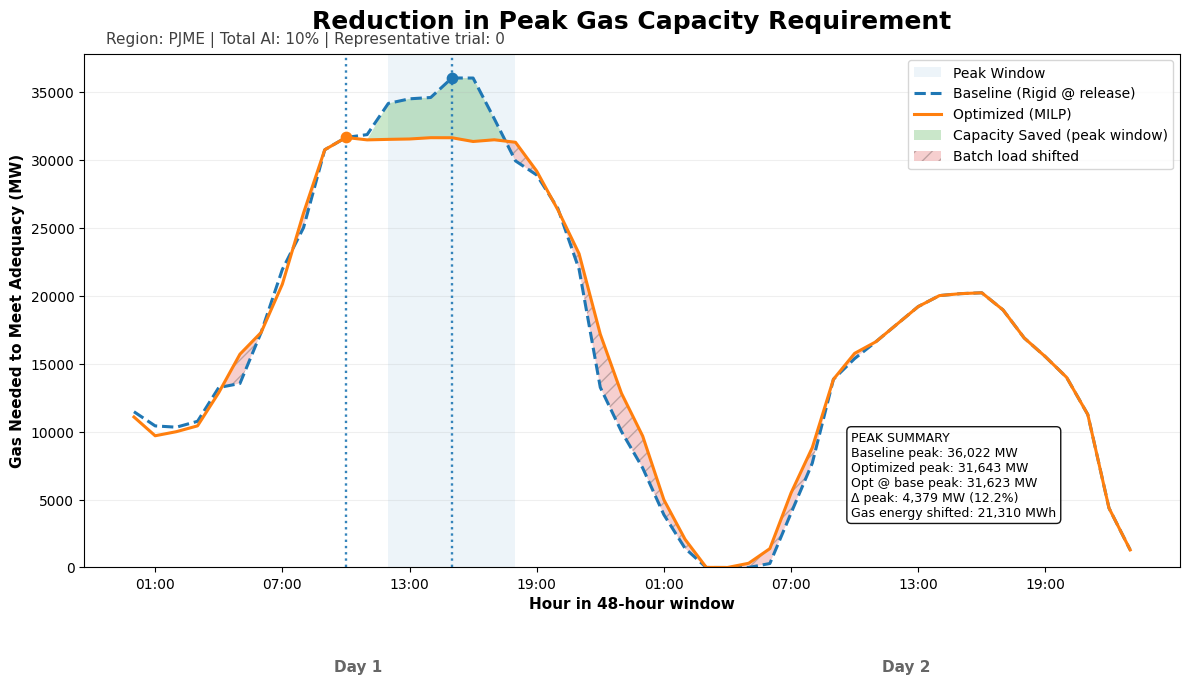

In [7]:
# @title Chart 1 (ALL REGIONS x ALL AI LEVELS, RULE-2 MEDIAN TRIAL, PRODUCTION-ALIGNED)
import os
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 0) CONFIG FROM GLOBALS
# =========================
BASE_DIR = globals().get(
    "BASE_DIR",
    "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
)

REGIONS = list(globals().get("REGIONS", ["PJME"]))
AI_LOAD_LEVELS = list(globals().get("AI_LOAD_LEVELS", [0.10, 0.20]))
STRESS_ALPHA = float(globals().get("STRESS_ALPHA", 0.6))
RHO = float(globals().get("RHO", 0.15))
IMPORT_LIMIT_MW = float(globals().get("IMPORT_LIMIT_MW", 5000.0))
PEAK_WINDOW_H = int(globals().get("PEAK_WINDOW_H", 6))
RESULTS_FILE = globals().get("RESULTS_FILE", "pareto_results.csv")

# Optional: if present, we use it; otherwise we infer trials from results/workloads
N_TRIALS_GLOBAL = globals().get("N_TRIALS", None)
WATER_WEIGHT_FOR_OPT = 0.0  # Chart 1: gas-only objective

# =========================
# 1) REQUIRE FUNCTIONS
# =========================
if "solve_milp_with_schedule" not in globals():
    raise RuntimeError("solve_milp_with_schedule not found. Run Cell 4 first.")
if "build_online_ai_load" not in globals():
    raise RuntimeError("build_online_ai_load not found. Run the cell that defines build_online_ai_load.")

# =========================
# 2) LOAD DATA
# =========================
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

results_path = os.path.join(BASE_DIR, RESULTS_FILE)
if not os.path.exists(results_path):
    raise FileNotFoundError(f"Cell 6 results file not found at: {results_path}")
results_df = pd.read_csv(results_path)

# =========================
# 3) HELPERS
# =========================
def schedule_rigid_at_release(jobs, T):
    """Rigid baseline: each job runs immediately at its release time r for d hours."""
    out = np.zeros(T, dtype=float)
    for j in jobs:
        p = float(j["p"])
        d = int(j["d"])
        r = int(j["r"])
        for t in range(r, min(r + d, T)):
            out[t] += p
    return out

def gas_needed_series(L_base, L_online, L_def, L_max, alpha, rho, import_limit):
    """Adequacy-implied gas per hour under your model."""
    C_non = alpha * float(L_max)
    L_total = np.asarray(L_base) + np.asarray(L_online) + np.asarray(L_def)
    gas = np.maximum(0.0, L_total * (1.0 + rho) - C_non - float(import_limit))
    return np.nan_to_num(gas, nan=0.0, posinf=0.0, neginf=0.0)

def c_total_from_def(L_base, L_online, L_def, L_max, alpha, rho, import_limit):
    """Compute C_total = C_non + max(gas_needed_series)."""
    C_non = alpha * float(L_max)
    gas = gas_needed_series(L_base, L_online, L_def, L_max, alpha, rho, import_limit)
    return float(C_non + np.max(gas)), gas

def load_jobs(region, ai_frac, trial):
    """Load the exact pre-generated jobs for (region, ai_frac, trial). Float-safe on ai_fraction."""
    wf = pd.to_numeric(workloads_df["ai_fraction"], errors="coerce").to_numpy()
    mask = (
        (workloads_df["region"].astype(str) == str(region)) &
        np.isclose(wf, float(ai_frac), atol=1e-6) &
        (pd.to_numeric(workloads_df["trial"], errors="coerce") == float(trial))
    )
    jdf = workloads_df.loc[mask]
    if len(jdf) == 0:
        return []
    return jdf[["id", "p", "d", "r", "e"]].to_dict("records")

def opt_c_total_from_results(region, ai_frac, trial, water_weight=0.0):
    """From Cell 6 results: total_peak_mw (= C_total) at a given water_weight."""
    rf = pd.to_numeric(results_df["ai_fraction"], errors="coerce").to_numpy()
    ww = pd.to_numeric(results_df["water_weight"], errors="coerce").to_numpy()
    mask = (
        (results_df["region"].astype(str) == str(region)) &
        np.isclose(rf, float(ai_frac), atol=1e-6) &
        (pd.to_numeric(results_df["trial"], errors="coerce") == float(trial)) &
        np.isclose(ww, float(water_weight), atol=1e-12)
    )
    sdf = results_df.loc[mask]
    if len(sdf) == 0:
        return np.nan
    return float(pd.to_numeric(sdf["total_peak_mw"], errors="coerce").iloc[0])

def available_trials(region, ai_frac):
    """
    Determine which trials exist for this (region, ai_frac).
    Prefer results_df at water_weight=0.0; fallback to workloads_df.
    """
    trials = set()

    # from results (preferred)
    rf = pd.to_numeric(results_df["ai_fraction"], errors="coerce")
    ww = pd.to_numeric(results_df["water_weight"], errors="coerce")
    m = (
        (results_df["region"].astype(str) == str(region)) &
        np.isclose(rf, float(ai_frac), atol=1e-6) &
        np.isclose(ww, 0.0, atol=1e-12)
    )
    if m.any():
        tvals = pd.to_numeric(results_df.loc[m, "trial"], errors="coerce").dropna().astype(int).tolist()
        trials.update(tvals)

    # fallback from workloads
    wf = pd.to_numeric(workloads_df["ai_fraction"], errors="coerce")
    m2 = (
        (workloads_df["region"].astype(str) == str(region)) &
        np.isclose(wf, float(ai_frac), atol=1e-6)
    )
    if m2.any():
        tvals2 = pd.to_numeric(workloads_df.loc[m2, "trial"], errors="coerce").dropna().astype(int).tolist()
        trials.update(tvals2)

    # if N_TRIALS is defined globally, restrict to [0..N_TRIALS-1]
    if N_TRIALS_GLOBAL is not None:
        n = int(N_TRIALS_GLOBAL)
        trials = {t for t in trials if 0 <= t < n}
        if len(trials) == 0:
            trials = set(range(n))

    return sorted(trials)

def plot_peak_gas_reduction(gas_base, gas_opt, region, ai_frac, peak_window_h, trial):
    hours = np.arange(len(gas_base))

    base_peak_t = int(np.argmax(gas_base))
    opt_peak_t  = int(np.argmax(gas_opt))

    base_max = float(gas_base[base_peak_t])
    opt_max  = float(gas_opt[opt_peak_t])
    opt_at_base_peak = float(gas_opt[base_peak_t])

    delta_max = base_max - opt_max
    pct = (delta_max / base_max * 100.0) if base_max > 1e-9 else 0.0

    half = peak_window_h // 2
    start = max(0, base_peak_t - half)
    end = min(len(hours), start + peak_window_h)

    shifted_mwh_gas = float(np.sum(np.clip(gas_opt - gas_base, 0, None)))  # 1h timestep

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.axvspan(start, end, alpha=0.08, label="Peak Window")

    ax.plot(hours, gas_base, linestyle="--", linewidth=2.2, label="Baseline (Rigid @ release)")
    ax.plot(hours, gas_opt,  linewidth=2.2, label="Optimized (MILP)")

    ax.scatter([base_peak_t], [base_max], s=55, zorder=5)
    ax.scatter([opt_peak_t],  [opt_max],  s=55, zorder=5)
    ax.axvline(base_peak_t, linestyle=":", linewidth=1.7, alpha=0.9)
    ax.axvline(opt_peak_t,  linestyle=":", linewidth=1.7, alpha=0.9)

    in_window = (hours >= start) & (hours < end)

    saved_mask = in_window & (gas_base > gas_opt)
    ax.fill_between(
        hours, gas_opt, gas_base,
        where=saved_mask,
        interpolate=True,
        alpha=0.25,
        label="Capacity Saved (peak window)"
    )

    shifted_mask = gas_opt > gas_base
    ax.fill_between(
        hours, gas_base, gas_opt,
        where=shifted_mask,
        interpolate=True,
        alpha=0.22,
        hatch="//",
        edgecolor="k",
        linewidth=0.0,
        label="Batch load shifted"
    )

    ax.set_title("Reduction in Peak Gas Capacity Requirement", fontsize=18, weight="bold", pad=18)
    ax.text(0.02, 1.02, f"Region: {region} | Total AI: {ai_frac:.0%} | Representative trial: {trial}",
            transform=ax.transAxes, fontsize=11, alpha=0.75)

    peak_txt = (
        "PEAK SUMMARY\n"
        f"Baseline peak: {base_max:,.0f} MW\n"
        f"Optimized peak: {opt_max:,.0f} MW\n"
        f"Opt @ base peak: {opt_at_base_peak:,.0f} MW\n"
        f"Δ peak: {delta_max:,.0f} MW ({pct:.1f}%)\n"
        f"Gas energy shifted: {shifted_mwh_gas:,.0f} MWh"
    )
    ax.text(0.70, 0.10, peak_txt, transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.92))

    ax.set_ylabel("Gas Needed to Meet Adequacy (MW)", fontsize=11, weight="bold")
    ax.set_xlabel("Hour in 48-hour window", fontsize=11, weight="bold")
    ax.grid(True, axis="y", alpha=0.2)
    ax.set_ylim(bottom=0)

    tick_pos = [1, 7, 13, 19, 25, 31, 37, 43]
    tick_lab = ["01:00", "07:00", "13:00", "19:00", "01:00", "07:00", "13:00", "19:00"]
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_lab)

    ax.text(0.25, -0.18, "Day 1", transform=ax.transAxes, ha="center", va="top",
            fontsize=11, weight="bold", alpha=0.6)
    ax.text(0.75, -0.18, "Day 2", transform=ax.transAxes, ha="center", va="top",
            fontsize=11, weight="bold", alpha=0.6)

    ax.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

def solve_once_get_deferr(L_base, L_online, jobs, w_vec):
    """Call your production solver in a signature-safe way and return deferr_mw."""
    sig = inspect.signature(solve_milp_with_schedule)
    kwargs = dict(
        L_base=L_base,
        L_online=L_online,
        jobs=jobs,
        alpha=STRESS_ALPHA,
        rho=RHO,
        water_weight=WATER_WEIGHT_FOR_OPT,
        import_limit_MW=IMPORT_LIMIT_MW
    )
    if "w_vec" in sig.parameters:
        kwargs["w_vec"] = w_vec  # production solver
    sol = solve_milp_with_schedule(**kwargs)
    status = sol.get("status", "Unknown")
    deferr = np.asarray(sol.get("deferr_mw", np.zeros(len(L_base))), dtype=float)
    return status, deferr

# =========================
# 4) MAIN LOOP: ALL REGIONS x ALL AI LEVELS
# =========================
print("\n=== CHART 1: ALL REGIONS x ALL AI LEVELS (REPRESENTATIVE MEDIAN TRIAL) ===")
for region_i, region in enumerate(REGIONS):

    region_window = windows_df[windows_df["region"].astype(str) == str(region)].sort_values("hour_idx")
    if len(region_window) == 0:
        print(f"[SKIP] No window data for region={region}")
        continue

    L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy()
    w_vec  = pd.to_numeric(region_window["water_m3_per_mwh"], errors="coerce").to_numpy()
    if len(L_base) == 0 or not np.isfinite(L_base).all():
        print(f"[SKIP] Bad L_base for region={region}")
        continue
    if len(w_vec) != len(L_base) or not np.isfinite(w_vec).all():
        print(f"[SKIP] Bad w_vec for region={region}")
        continue

    T = int(len(L_base))
    L_max = float(np.max(L_base))

    for ai_i, ai_frac in enumerate(AI_LOAD_LEVELS):
        ai_frac = float(ai_frac)
        trials = available_trials(region, ai_frac)
        if len(trials) == 0:
            print(f"[SKIP] No trials found for region={region}, ai_frac={ai_frac}")
            continue

        # 50/50 split must match Cell 6
        ai_online_portion = 0.5 * ai_frac

        # ---- Rule 2: compute peak reduction for each trial using Cell 6 optimized C_total ----
        rows = []
        for trial in trials:
            # online load must match Cell 6 seed logic
            seed = int(trial + 10_000 * region_i + 1_000_000 * ai_i)
            rng = np.random.default_rng(seed)
            L_online = np.asarray(build_online_ai_load(region_window, L_max, ai_online_portion, rng), dtype=float)
            if len(L_online) != T or not np.isfinite(L_online).all():
                continue

            jobs = load_jobs(region, ai_frac, trial)
            if len(jobs) == 0:
                continue

            # baseline capacity from rigid schedule (no optimization)
            def_base = schedule_rigid_at_release(jobs, T)
            C_base, _ = c_total_from_def(L_base, L_online, def_base, L_max, STRESS_ALPHA, RHO, IMPORT_LIMIT_MW)

            # optimized capacity from Cell 6 (water_weight=0)
            C_opt = opt_c_total_from_results(region, ai_frac, trial, water_weight=0.0)
            if not np.isfinite(C_opt):
                continue

            rows.append((trial, C_base, C_opt, C_base - C_opt))

        if len(rows) == 0:
            print(f"[SKIP] Could not compute median selection for region={region}, ai_frac={ai_frac}")
            continue

        reductions = np.array([r[3] for r in rows], dtype=float)
        med = float(np.median(reductions))
        rep_trial, rep_Cbase, rep_Copt, rep_red = min(rows, key=lambda x: abs(x[3] - med))

        print(f"\nRegion={region} | AI={ai_frac:.0%} | Representative trial={rep_trial}")
        print(f"  Baseline C_total={rep_Cbase:,.1f} | Opt C_total(from results)={rep_Copt:,.1f} | Δ={rep_red:,.1f} | median Δ={med:,.1f}")

        # ---- Re-solve that representative trial ONCE to get time-series schedule ----
        seed = int(rep_trial + 10_000 * region_i + 1_000_000 * ai_i)
        rng = np.random.default_rng(seed)
        L_online = np.asarray(build_online_ai_load(region_window, L_max, ai_online_portion, rng), dtype=float)

        jobs = load_jobs(region, ai_frac, rep_trial)
        def_base = schedule_rigid_at_release(jobs, T)

        status, def_opt = solve_once_get_deferr(L_base, L_online, jobs, w_vec)
        if status not in ("Optimal", "Not Solved"):
            print(f"  [SKIP PLOT] solver status={status}")
            continue

        gas_base = gas_needed_series(L_base, L_online, def_base, L_max, STRESS_ALPHA, RHO, IMPORT_LIMIT_MW)
        gas_opt  = gas_needed_series(L_base, L_online, def_opt,  L_max, STRESS_ALPHA, RHO, IMPORT_LIMIT_MW)

        plot_peak_gas_reduction(gas_base, gas_opt, region=region, ai_frac=ai_frac, peak_window_h=PEAK_WINDOW_H, trial=rep_trial)


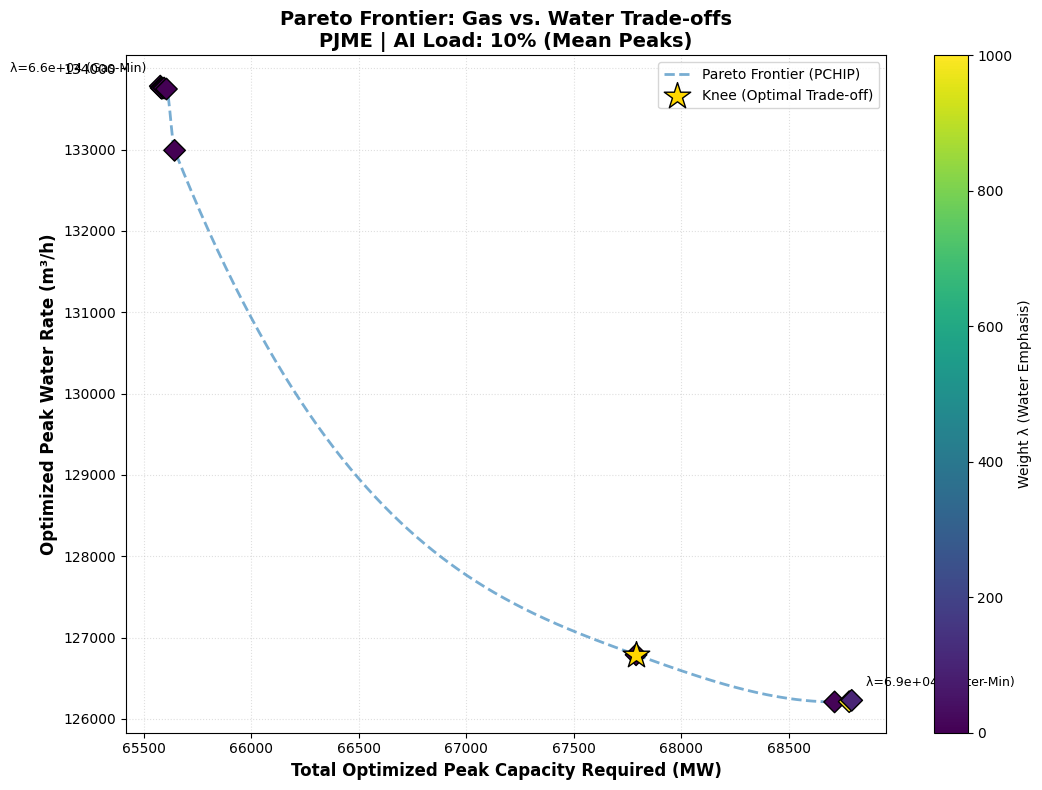

In [6]:
# @title Chart 2 PARETO FRONTIER VISUALIZATION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import os

# 1. Load the optimized results
res_path = os.path.join(BASE_DIR, RESULTS_FILE)
if not os.path.exists(res_path):
    raise FileNotFoundError(f"Results file not found at {res_path}. Please run Cell 6 first.")

df = pd.read_csv(res_path)

# 2. Filter for the specific scenario to plot
target_region = df['region'].unique()[0]
target_ai = df['ai_fraction'].max()  # Usually 0.30/30% AI load
plot_df = df[(df['region'] == target_region) & (df['ai_fraction'] == target_ai)].copy()

# 3. Aggregate Trial Data (Mean across N=50)
summary = plot_df.groupby('water_weight').agg({
    'total_peak_mw': 'mean',
    'water_peak_m3h': 'mean'
}).reset_index().sort_values('total_peak_mw')

# Clean duplicates to ensure strictly increasing X for PCHIP
summary = summary.drop_duplicates(subset=['total_peak_mw'], keep='last')
x = summary['total_peak_mw'].values
y = summary['water_peak_m3h'].values

# 4. Visualization Logic
plt.figure(figsize=(11, 8), dpi=100)
ax = plt.gca()

if len(x) >= 3:
    # Generate smooth PCHIP curve
    x_smooth = np.linspace(x.min(), x.max(), 500)
    pchip = PchipInterpolator(x, y)
    y_smooth = pchip(x_smooth)
    plt.plot(x_smooth, y_smooth, 'tab:blue', linestyle='--', linewidth=2, alpha=0.6, label='Pareto Frontier (PCHIP)')

    # Automated "Knee" Detection (Normalizing to find max curvature)
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    knee_idx = np.argmin(np.sqrt(x_norm**2 + y_norm**2))
    plt.scatter(x[knee_idx], y[knee_idx], color='gold', marker='*', s=400, edgecolors='black', zorder=10, label='Knee (Optimal Trade-off)')
else:
    plt.plot(x, y, 'tab:blue', linestyle='--', alpha=0.6)

# Scatter plot of individual weights
sc = plt.scatter(x, y, c=summary['water_weight'], cmap='viridis', s=120, marker='D', edgecolors='k', zorder=5)

# 5. Formatting
plt.title(f"Pareto Frontier: Gas vs. Water Trade-offs\n{target_region} | AI Load: {int(target_ai*100)}% (Mean Peaks)", fontsize=14, fontweight='bold')
plt.xlabel("Total Optimized Peak Capacity Required (MW)", fontsize=12, fontweight='bold')
plt.ylabel("Optimized Peak Water Rate (m³/h)", fontsize=12, fontweight='bold')
plt.colorbar(sc, label='Weight λ (Water Emphasis)')
plt.grid(True, which='both', linestyle=':', alpha=0.4)
plt.legend()

# Endpoint Annotations
plt.annotate(f'λ={x[0]:.1e} (Gas-Min)', (x[0], y[0]), textcoords="offset points", xytext=(-10,10), ha='right', fontsize=9)
plt.annotate(f'λ={x[-1]:.1e} (Water-Min)', (x[-1], y[-1]), textcoords="offset points", xytext=(10,10), ha='left', fontsize=9)

plt.tight_layout()
plt.show()



---



In [26]:
# @title Chart 3: FINAL REGIONAL HEADLINE IMPACT SUMMARY (CONFIG-DRIVEN, ROBUST)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- helpers ----------
def _mean_ci95(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n == 0:
        return np.nan, np.nan, 0
    m = float(np.mean(x))
    if n == 1:
        return m, 0.0, 1
    se = float(np.std(x, ddof=1) / np.sqrt(n))
    return m, 1.96 * se, n  # ~95% CI (normal approx; fine for n>=5)

def _agg_mean_ci(df, group_cols, value_col):
    rows = []
    for keys, g in df.groupby(group_cols, dropna=False):
        m, ci, n = _mean_ci95(g[value_col].to_numpy())
        if not isinstance(keys, tuple):
            keys = (keys,)
        rows.append((*keys, m, ci, n))
    out = pd.DataFrame(rows, columns=[*group_cols, "mean", "ci95", "n"])
    return out

# Colorblind-safe palette (Okabe–Ito)
COLORS = {
    "blue":  "#0072B2",
    "orange":"#E69F00",
    "green": "#009E73",
    "gray":  "#444444",
    "light": "#EEEEEE",
    "note":  "#666666"
}

def _ensure_units(df):
    """Add avoided_capacity_gw if avoided_capacity_mw exists."""
    df = df.copy()
    if ("avoided_capacity_mw" in df.columns) and ("avoided_capacity_gw" not in df.columns):
        df["avoided_capacity_gw"] = df["avoided_capacity_mw"] / 1000.0
    return df

def plot_regional_headline(df,
                           ai_level,
                           region_col="region",
                           ai_col="ai_fraction",
                           metrics=("avoided_capacity_gw", "peak_reduction_pct", "water_saved_absolute"),
                           metric_titles=("INFRASTRUCTURE", "GRID STRESS", "WATER STRESS"),
                           ylabels=("Avoided peak gas capacity (GW)",
                                    "Peak capacity reduction (%)",
                                    "Peak water-rate reduction (m³/h)"),
                           note_water_coverage=True,
                           figsize=(12.5, 3.6)):

    d = _ensure_units(df)

    needed = [region_col, ai_col, *metrics]
    miss = [c for c in needed if c not in d.columns]
    if miss:
        raise ValueError(
            "Chart 2 needs headline-metric columns that are not in this dataframe.\n"
            f"Missing columns: {miss}\n\n"
            "This chart expects a post-processing step that computes:\n"
            "  - avoided_capacity_gw (or avoided_capacity_mw)\n"
            "  - peak_reduction_pct\n"
            "  - water_saved_absolute\n"
        )

    d = d.loc[np.isclose(pd.to_numeric(d[ai_col], errors="coerce"), float(ai_level), atol=1e-9)].copy()
    if d.empty:
        raise ValueError(f"No rows found for {ai_col} == {ai_level}. Check AI_LOAD_LEVELS vs results_df.")

    # Order regions by infrastructure impact (mean)
    infra = _agg_mean_ci(d, [region_col], metrics[0]).sort_values("mean", ascending=False)
    order = infra[region_col].astype(str).tolist()

    fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True)
    fig.suptitle(
        f"Regional Headline Impacts (AI Load = {int(round(ai_level*100))}%)",
        fontsize=14, fontweight="bold", y=1.05
    )

    # Subtitle with sample size info (judge-friendly)
    # (mean n across regions for the first metric)
    mean_n = int(np.nanmean(infra["n"].to_numpy()))
    fig.text(0.5, 0.98, f"Bars show mean across trials; error bars = 95% CI (N≈{mean_n}).",
             ha="center", va="top", fontsize=9, color=COLORS["note"])

    for ax, metric, title, yl in zip(axes, metrics, metric_titles, ylabels):
        s = _agg_mean_ci(d, [region_col], metric)
        s[region_col] = s[region_col].astype(str)
        s[region_col] = pd.Categorical(s[region_col], categories=order, ordered=True)
        s = s.sort_values(region_col)

        x = np.arange(len(order))
        y = s["mean"].to_numpy()
        ci = s["ci95"].to_numpy()

        # If water metric has missing/NaN for a region, show as 0 height + hatch + label
        missing_mask = ~np.isfinite(y)
        y_plot = y.copy()
        ci_plot = ci.copy()
        y_plot[missing_mask] = 0.0
        ci_plot[missing_mask] = 0.0

        bars = ax.bar(
            x, y_plot,
            yerr=ci_plot,
            capsize=3,
            color=COLORS["blue"],
            alpha=0.90,
            edgecolor="black",
            linewidth=0.6,
            error_kw=dict(ecolor=COLORS["gray"], lw=0.9, alpha=0.65),
            zorder=3
        )

        # Hatch missing values (most important for water panel / AEP issue)
        for i, is_missing in enumerate(missing_mask):
            if is_missing:
                bars[i].set_hatch("//")
                bars[i].set_alpha(0.35)

        ax.set_title(title, fontweight="bold", pad=8, fontsize=10)
        ax.set_ylabel(yl, fontweight="bold")

        ax.set_xticks(x)
        ax.set_xticklabels(order)

        # Cleaner formatting
        if metric == "peak_reduction_pct":
            ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
        else:
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)
            ax.get_yaxis().set_major_formatter(
                plt.FuncFormatter(lambda v, _: f"{int(v):,}" if abs(v) >= 1000 else f"{v:g}")
            )

        ax.grid(axis="y", linestyle=":", alpha=0.22)
        ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_alpha(0.25)

        if note_water_coverage and title == "WATER STRESS":
            ax.text(
                0.98, 0.98,
                "Note: hatched bars = insufficient\nwater-intensity coverage (N too low).",
                transform=ax.transAxes,
                ha="right", va="top",
                fontsize=9, color=COLORS["note"],
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.9, edgecolor="0.6")
            )

    plt.show()


def plot_scaling_curve(df,
                       region,
                       region_col="region",
                       ai_col="ai_fraction",
                       metrics=("avoided_capacity_gw", "peak_reduction_pct", "water_saved_absolute"),
                       metric_titles=("Avoided peak gas capacity", "Peak capacity reduction", "Peak water-rate reduction"),
                       ylabels=("Avoided peak gas capacity (GW)",
                                "Peak capacity reduction (%)",
                                "Peak water-rate reduction (m³/h)"),
                       figsize=(12.5, 3.6)):

    d = _ensure_units(df)

    needed = [region_col, ai_col, *metrics]
    miss = [c for c in needed if c not in d.columns]
    if miss:
        raise ValueError(f"Missing columns for scaling curve: {miss}")

    d = d.loc[d[region_col].astype(str) == str(region)].copy()
    if d.empty:
        raise ValueError(f"No rows found for region == {region}")

    ai_levels = sorted([float(x) for x in pd.to_numeric(d[ai_col], errors="coerce").dropna().unique()])
    xs = np.array([int(round(a * 100)) for a in ai_levels], dtype=float)

    fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True)
    fig.suptitle(f"Scaling with Flexible AI Load (Region: {region})",
                 fontsize=14, fontweight="bold")

    for ax, metric, ttl, yl in zip(axes, metrics, metric_titles, ylabels):
        rows = []
        for a in ai_levels:
            vals = d.loc[np.isclose(pd.to_numeric(d[ai_col], errors="coerce"), a, atol=1e-9), metric].to_numpy()
            m, ci, n = _mean_ci95(vals)
            rows.append((a, m, ci, n))
        s = pd.DataFrame(rows, columns=[ai_col, "mean", "ci95", "n"]).sort_values(ai_col)

        y = s["mean"].to_numpy()
        ci = s["ci95"].to_numpy()

        ax.plot(xs, y, marker="o", linewidth=2.2, color=COLORS["blue"], zorder=4)
        ax.errorbar(xs, y, yerr=ci, fmt="none", ecolor=COLORS["gray"],
                    elinewidth=0.9, capsize=2, alpha=0.35, zorder=3)

        ax.set_title(ttl, fontweight="bold", pad=6, fontsize=10)
        ax.set_ylabel(yl, fontweight="bold")
        ax.set_xlabel("AI Load (%)", fontweight="bold")

        ax.set_xticks(xs)
        ax.set_xticklabels([f"{int(v)}%" for v in xs])

        ax.grid(axis="y", linestyle=":", alpha=0.22)
        ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_alpha(0.25)

        if metric == "peak_reduction_pct":
            ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
        else:
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)
            ax.get_yaxis().set_major_formatter(
                plt.FuncFormatter(lambda v, _: f"{int(v):,}" if abs(v) >= 1000 else f"{v:g}")
            )

    plt.show()


# ---------- RUN: all regions x all AI levels ----------
# expects results_df already exists
ai_levels_to_plot = sorted([float(x) for x in pd.to_numeric(results_df["ai_fraction"], errors="coerce").dropna().unique()])
regions_to_plot = [str(r) for r in results_df["region"].astype(str).dropna().unique()]

for a in ai_levels_to_plot:
    plot_regional_headline(results_df, ai_level=a)

for r in regions_to_plot:
    plot_scaling_curve(results_df, region=r)


ValueError: Chart 2 needs headline-metric columns that are not in this dataframe.
Missing columns: ['avoided_capacity_gw', 'peak_reduction_pct', 'water_saved_absolute']

This chart expects a post-processing step that computes:
  - avoided_capacity_gw (or avoided_capacity_mw)
  - peak_reduction_pct
  - water_saved_absolute


In [25]:
# @title Post-process: Build Headline Metrics (baseline vs representative optimized)
import os
import numpy as np
import pandas as pd

# ---------- helpers ----------
def schedule_baseline_rigid_at_release(jobs, T):
    """
    Baseline deferrable schedule: run each job immediately at release for d hours (contiguous),
    shifting to latest feasible start only if needed to fit in [r,e).
    """
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        p = float(j["p"])
        d = int(j["d"])
        r = int(j["r"])
        e = int(j["e"])
        start = r
        if start + d > e:
            start = max(r, e - d)
        for t in range(start, start + d):
            if 0 <= t < T:
                deferr[t] += p
    return deferr

def compute_peaks(L_base, L_online, L_def, w_vec, alpha, rho, import_limit_MW):
    """
    Recompute peak capacity requirement and peak water rate using the same adequacy framing as the MILP.
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    L_def = np.asarray(L_def, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    L_max = float(np.max(L_base))
    C_non = alpha * L_max

    L_total = L_base + L_online + L_def
    gas_needed = np.maximum(0.0, L_total * (1.0 + rho) - C_non - float(import_limit_MW))

    C_total_peak = C_non + float(np.max(gas_needed))
    W_peak = float(np.max(L_total * w_vec))
    return C_total_peak, W_peak

def pick_representative_lambda(res_sub):
    """
    res_sub: rows for a single (region, ai_fraction) across trials & weights.
    Pick λ that is closest to ideal point (min x, min y) after normalization.
    """
    # mean across trials at each lambda
    summary = res_sub.groupby("water_weight", as_index=False).agg(
        total_peak_mw=("total_peak_mw", "mean"),
        water_peak_m3h=("water_peak_m3h", "mean"),
    )

    if len(summary) == 0:
        return None

    x = summary["total_peak_mw"].to_numpy(dtype=float)
    y = summary["water_peak_m3h"].to_numpy(dtype=float)

    # normalize to [0,1] robustly
    x_rng = (np.max(x) - np.min(x)) or 1.0
    y_rng = (np.max(y) - np.min(y)) or 1.0
    x_n = (x - np.min(x)) / x_rng
    y_n = (y - np.min(y)) / y_rng

    dist = np.sqrt(x_n**2 + y_n**2)  # distance to ideal (0,0)
    idx = int(np.argmin(dist))
    return float(summary.loc[idx, "water_weight"])

def nearest_weight_row(df_trial, target_w):
    """Pick row in df_trial whose water_weight is closest to target_w."""
    ww = df_trial["water_weight"].to_numpy(dtype=float)
    idx = int(np.argmin(np.abs(ww - float(target_w))))
    return df_trial.iloc[idx]

# ---------- load raw outputs ----------
res_path = os.path.join(BASE_DIR, RESULTS_FILE)
if not os.path.exists(res_path):
    raise FileNotFoundError(f"Run Cell 6 first. Missing: {res_path}")

windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))
results_raw = pd.read_csv(res_path)

# Float-safe types
results_raw["ai_fraction"] = pd.to_numeric(results_raw["ai_fraction"], errors="coerce")
results_raw["trial"] = pd.to_numeric(results_raw["trial"], errors="coerce").astype("Int64")
results_raw["water_weight"] = pd.to_numeric(results_raw["water_weight"], errors="coerce")
results_raw["total_peak_mw"] = pd.to_numeric(results_raw["total_peak_mw"], errors="coerce")
results_raw["water_peak_m3h"] = pd.to_numeric(results_raw["water_peak_m3h"], errors="coerce")

# Build index maps for seed logic (must match Cell 6)
region_to_i = {str(r): i for i, r in enumerate(REGIONS)}
ai_levels = [float(a) for a in AI_LOAD_LEVELS]
ai_to_i = {a: i for i, a in enumerate(ai_levels)}

# ---------- compute headline metrics ----------
rows = []

for region in REGIONS:
    rkey = str(region)

    region_window = windows_df[windows_df["region"].astype(str) == rkey].sort_values("hour_idx")
    if len(region_window) == 0:
        print(f"[WARN] Missing window for {region}; skipping.")
        continue

    L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy(dtype=float)
    w_vec  = pd.to_numeric(region_window["water_m3_per_mwh"], errors="coerce").to_numpy(dtype=float)
    T = len(L_base)
    L_max = float(np.max(L_base))

    for ai_frac in ai_levels:
        # Find representative λ for this region+ai using mean peaks across trials
        sub = results_raw[(results_raw["region"].astype(str) == rkey) &
                          (np.isclose(results_raw["ai_fraction"], ai_frac, atol=1e-9))]
        if len(sub) == 0:
            print(f"[WARN] No Pareto results for {region}, AI={ai_frac}; skipping.")
            continue

        rep_lambda = pick_representative_lambda(sub)
        if rep_lambda is None:
            print(f"[WARN] Could not pick representative λ for {region}, AI={ai_frac}.")
            continue

        ai_online_portion = 0.5 * ai_frac  # per your calibration

        for trial in range(int(N_TRIALS)):
            # reproduce online AI
            seed = int(trial + 10_000*region_to_i[rkey] + 1_000_000*ai_to_i[ai_frac])
            rng = np.random.default_rng(seed)
            L_online = build_online_ai_load(region_window, L_max, ai_online_portion, rng)

            # load jobs for this trial
            jobs_df = workloads_df[
                (workloads_df["region"].astype(str) == rkey) &
                (np.isclose(pd.to_numeric(workloads_df["ai_fraction"], errors="coerce"), ai_frac, atol=1e-9)) &
                (pd.to_numeric(workloads_df["trial"], errors="coerce") == float(trial))
            ]
            if len(jobs_df) == 0:
                print(f"[WARN] Missing jobs for {region}, AI={ai_frac}, trial={trial}; skipping trial.")
                continue
            jobs = jobs_df[["id","p","d","r","e"]].to_dict("records")

            # baseline peaks (rigid)
            L_def_base = schedule_baseline_rigid_at_release(jobs, T)
            C_base, W_base = compute_peaks(L_base, L_online, L_def_base, w_vec,
                                           alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW)

            # optimized peaks at representative λ (from Cell 6 results)
            trial_rows = sub[sub["trial"] == trial]
            if len(trial_rows) == 0:
                print(f"[WARN] Missing results for {region}, AI={ai_frac}, trial={trial}; skipping trial.")
                continue
            r = nearest_weight_row(trial_rows, rep_lambda)

            C_opt = float(r["total_peak_mw"])
            W_opt = float(r["water_peak_m3h"])

            # reductions (clip to 0 for “avoided/reduced” interpretation)
            avoided_capacity_mw = max(0.0, C_base - C_opt)
            avoided_capacity_gw = avoided_capacity_mw / 1000.0
            peak_reduction_pct  = (avoided_capacity_mw / C_base * 100.0) if C_base > 0 else np.nan
            water_saved_absolute = max(0.0, W_base - W_opt)

            rows.append({
                "region": rkey,
                "ai_fraction": float(ai_frac),
                "trial": int(trial),
                "rep_lambda": float(rep_lambda),
                "baseline_peak_mw": float(C_base),
                "optimized_peak_mw": float(C_opt),
                "baseline_water_peak_m3h": float(W_base),
                "optimized_water_peak_m3h": float(W_opt),
                "avoided_capacity_mw": float(avoided_capacity_mw),
                "avoided_capacity_gw": float(avoided_capacity_gw),
                "peak_reduction_pct": float(peak_reduction_pct),
                "water_saved_absolute": float(water_saved_absolute),
            })

headline_df = pd.DataFrame(rows)
print("Headline metrics ready:", headline_df.shape)
headline_df.head()


Headline metrics ready: (5, 12)


,region,ai_fraction,trial,rep_lambda,baseline_peak_mw,optimized_peak_mw,baseline_water_peak_m3h,optimized_water_peak_m3h,avoided_capacity_mw,avoided_capacity_gw,peak_reduction_pct,water_saved_absolute
0,PJME,0.1,0,1.0,68599.273621,66004.250,139356.838079,126261.638533,2595.023621,2.595024,3.782873,13095.199545
1,PJME,0.1,1,1.0,70285.794761,68692.173,140457.618074,127968.462322,1593.621761,1.593622,2.267345,12489.155752
2,PJME,0.1,2,1.0,70749.898155,68509.775,137319.103447,127689.298119,2240.123155,2.240123,3.166256,9629.805328
3,PJME,0.1,3,1.0,67782.295900,67066.082,134628.850481,124312.560232,716.213900,0.716214,1.056639,10316.290248
4,PJME,0.1,4,1.0,71868.128902,68679.097,137913.156676,127714.919831,3189.031902,3.189032,4.437338,10198.236845


In [20]:
# @title 6. SPEED-OPTIMIZED MAIN LOOP (PRODUCTION-SAFE) -- disables on 1/4 7:24pm
import pandas as pd
import numpy as np
import os

print("\n=== STARTING OPTIMIZED PARETO STUDY ===")

# 1) LOAD PRE-CALCULATED DATA
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))
results = []

# Float-safe ai_fraction matching
wf = pd.to_numeric(workloads_df["ai_fraction"], errors="coerce")

# Optional: build a fast lookup map (speeds up filtering when data grows)
# Keys are (region, ai_fraction_value_as_float, trial_int)
jobs_map = {}
for (r, a, tr), grp in workloads_df.dropna(subset=["ai_fraction", "trial"]).groupby(["region", "ai_fraction", "trial"]):
    try:
        jobs_map[(str(r), float(a), int(tr))] = grp.to_dict("records")
    except Exception:
        pass

def get_trial_jobs(region: str, ai_frac: float, trial: int, atol: float = 1e-6):
    """
    Retrieve jobs for (region, ai_frac, trial) with float-safe ai_fraction matching.
    Uses jobs_map if possible, otherwise falls back to filtering.
    """
    # Try direct exact-float key first (common case if CSV wrote clean decimals)
    key_exact = (str(region), float(ai_frac), int(trial))
    if key_exact in jobs_map:
        return jobs_map[key_exact]

    # Fall back: search nearby ai_fraction keys for this region/trial
    # (handles float precision issues)
    candidates = []
    for (r, a, tr) in jobs_map.keys():
        if r == str(region) and tr == int(trial) and abs(a - float(ai_frac)) <= atol:
            candidates.append(jobs_map[(r, a, tr)])

    if candidates:
        a_best, jobs_best = min(candidates, key=lambda x: abs(x[0] - float(ai_frac)))
        return jobs_best

    # if candidates:
    #     # If multiple match, pick the closest
    #     # (usually there will be exactly one)
    #     best = min(
    #         [(abs(list(jobs_map.keys())[0][1] - ai_frac), c) for c in candidates],
    #         key=lambda x: x[0]
    #     )[1]
    #     return best

    # Ultimate fallback: filter the dataframe (still float-safe)
    return workloads_df[
        (workloads_df["region"].astype(str) == str(region)) &
        np.isclose(wf, float(ai_frac), atol=atol) &
        (pd.to_numeric(workloads_df["trial"], errors="coerce") == float(trial))
    ].to_dict("records")


# 2) REGIONAL PROCESSING LOOP
for region_i, region in enumerate(REGIONS):
    print(f"\nProcessing Region: {region}...")

    # Extract pre-cleaned window and hourly water intensity
    region_window = windows_df[windows_df["region"].astype(str) == str(region)].sort_values("hour_idx")
    if len(region_window) == 0:
        print(f"  [WARN] No window found for region={region}. Skipping.")
        continue

    L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy()
    w_vec  = pd.to_numeric(region_window["water_m3_per_mwh"], errors="coerce").to_numpy()

    if len(L_base) == 0 or not np.isfinite(L_base).all():
        print(f"  [WARN] L_base is empty or has NaN/Inf for region={region}. Skipping.")
        continue
    if len(w_vec) != len(L_base) or not np.isfinite(w_vec).all():
        raise ValueError(f"w_vec length mismatch or NaN/Inf for region={region}")

    L_max = float(np.max(L_base))
    T = int(len(L_base))

    # 3) AI LOAD LEVEL LOOP
    for ai_i, ai_frac in enumerate(AI_LOAD_LEVELS):
        print(f" -> AI Level: {int(ai_frac*100)}%")

        # CALIBRATION: Split total AI into 50% Online and 50% Deferrable
        ai_online_portion = 0.5 * float(ai_frac)

        # 4) STOCHASTIC TRIAL LOOP
        for trial in range(N_TRIALS):
            # REPRODUCIBILITY: same seed logic as Cell 5
            seed = int(trial + 10_000*region_i + 1_000_000*ai_i)
            rng = np.random.default_rng(seed)

            # Load the EXACT pre-generated deferrable workload for this trial
            trial_jobs = get_trial_jobs(region, float(ai_frac), int(trial), atol=1e-6)
            if len(trial_jobs) == 0:
                print(f"   [WARN] No jobs found for region={region}, ai={ai_frac}, trial={trial}. Skipping trial.")
                continue

            # Generate the non-deferrable (always-on) AI component
            # Assumes your build_online_ai_load signature is:
            # build_online_ai_load(region_window, L_max, ai_online_portion, rng)
            L_online = build_online_ai_load(region_window, L_max, ai_online_portion, rng)

            if len(L_online) != T or not np.isfinite(L_online).all():
                raise ValueError(f"L_online invalid (len/NaN) for region={region}, ai={ai_frac}, trial={trial}")

            # 5) PARETO WEIGHT LOOP
            for w_weight in PARETO_WEIGHTS:
                sol = solve_milp_with_schedule(
                    L_base=L_base,
                    L_online=L_online,
                    jobs=trial_jobs,
                    w_vec=w_vec,
                    alpha=STRESS_ALPHA,
                    rho=RHO,  # use config, not a hardcode
                    water_weight=w_weight,
                    import_limit_MW=IMPORT_LIMIT_MW
                )

                # 6) LOG SUCCESSFUL TRIALS
                if sol.get("status") in ("Optimal", "Not Solved"):
                    results.append({
                        "region": region,
                        "ai_fraction": float(ai_frac),
                        "trial": int(trial),
                        "water_weight": float(w_weight),
                        "total_peak_mw": float(sol["C_total"]),  # Combined Non-gas + Gas Peak
                        "water_peak_m3h": float(sol["W_peak"])   # True peak (max(L_tot*w_vec))
                    })

# 7) SAVE FINAL RESULTS
if results:
    res_df = pd.DataFrame(results)
    res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
    print(f"\nSuccess! Scientific results saved to: {RESULTS_FILE}")
else:
    print("\nWarning: No optimal solutions found. Check Solver or Grid Stress parameters.")



=== STARTING OPTIMIZED PARETO STUDY ===

Processing Region: PJME...
 -> AI Level: 10%
 -> AI Level: 20%


KeyboardInterrupt: 



---





---



In [2]:
# @title 4. WORKLOAD GENERATION & SOLVER FUNCTIONS - OLD IGNORE
import pulp
import numpy as np
import pandas as pd


# ==========================================
# A. STOCHASTIC JOB GENERATOR
# ==========================================
def generate_jobs_stochastic(T, t_peak, L_max, rng,
                             base_rate=0.6, peak_amp=1.5, peak_sigma=8,
                             slack_regime="loose"):
    """
    Generates a list of AI training jobs with stochastic arrival and flexibility.
    - Arrival times follow a Gaussian distribution centered at t_peak.
    - Slack (flexibility) is determined by the slack_regime.
    """
    jobs = []

    # 1. Determine total number of jobs based on peak load scaling
    n_jobs = int(L_max * 0.1)  # Heuristic for AI fleet size

    # 2. Sample Arrival Times (Gaussian distribution around grid peak)
    arrivals = rng.normal(t_peak, peak_sigma, n_jobs)
    arrivals = np.clip(arrivals, 0, T-1).astype(int)

    # 3. Define Slack Ranges based on regime
    slack_map = {
        "tight": (1, 4),
        "medium": (6, 12),
        "loose": (12, 24) # Allows significant shifting to low-water hours
    }
    s_min, s_max = slack_map.get(slack_regime, (6, 12))

    for i in range(n_jobs):
        p_val = rng.uniform(0.01 * L_max, 0.05 * L_max) # Power demand per job
        d_val = rng.integers(2, 8)                       # Duration in hours
        release = arrivals[i]

        # Calculate deadline based on slack
        slack = rng.integers(s_min, s_max + 1)
        deadline = min(T, release + d_val + slack)

        jobs.append({
            "id": i,
            "p": p_val,
            "d": d_val,
            "r": release,
            "e": deadline
        })
    return jobs

# ==========================================
# B. MILP OPTIMIZATION SOLVER
# ==========================================
def solve_milp(L_base, L_online, jobs, w_vec,
               alpha=0.5, rho=0.15, water_weight=0.0,
               include_thermal=False, import_limit_MW=0.0):
    """
    Solves the Mixed-Integer Linear Program to minimize Gas Capacity and Water.
    Minimize: C_gas + (water_weight * W_peak).
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex", pulp.LpMinimize)

    # --- Variables ---
    C_gas = pulp.LpVariable("C_gas", lowBound=0) # Local Gas Capacity required
    W_peak = pulp.LpVariable("W_peak", lowBound=0) # Peak Water Intensity (m3/h)

    # Decision variable: x[j, t] = 1 if job j is running at time t
    x = pulp.LpVariable.dicts("x",
                              ((j['id'], t) for j in jobs for t in range(T)),
                              cat=pulp.LpBinary)

    # --- Objective Function ---
    # Minimizing the trade-off between gas infrastructure and peak water usage
    prob += C_gas + (water_weight * W_peak)

    # --- Constraints ---
    C_non = alpha * np.max(L_base) # Baseline non-gas capacity

    for t in range(T):
        # 1. Total Load Calculation
        ai_deferrable = pulp.lpSum([j['p'] * x[j['id'], t] for j in jobs])
        L_total = L_base[t] + L_online[t] + ai_deferrable

        # 2. Grid Adequacy Constraint
        # All demand must be met by (Non-gas + Local Gas + Imports)
        prob += L_total * (1 + rho) <= C_non + C_gas + import_limit_MW

        # 3. Water Peak Constraint
        # Tracks the maximum water consumption across the horizon
        prob += L_total * w_vec[t] <= W_peak

    # 4. Job Completion Constraints
    for j in jobs:
        # Every job must run for its required duration
        prob += pulp.lpSum([x[j['id'], t] for t in range(j['r'], j['e'])]) == j['d']

        # Job cannot run before release or after deadline
        prob += pulp.lpSum([x[j['id'], t] for t in range(T) if t < j['r'] or t >= j['e']]) == 0

    # --- Solve ---
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30) # 30s limit to keep loop moving
    #solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, fractionGap=0.01)
    prob.solve(solver)

    status = pulp.LpStatus[prob.status]
    return {
        "status": status,
        "C_peak": pulp.value(C_gas) if status == "Optimal" else None,
        "W_peak": pulp.value(W_peak) if status == "Optimal" else None
    }


##########################################################################

def solve_milp_with_schedule(L_base, L_online, jobs, alpha=0.2, rho=0.15,
                             water_weight=0.0, import_limit_MW=0.0):
    """
    Solves the MILP and returns the hourly deferrable load profile.
    Adequacy: L_total * (1 + rho) <= C_non + C_gas + Imports
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex_Schedule", pulp.LpMinimize)

    # Variables: Infrastructure and Job Timing
    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)
    x = pulp.LpVariable.dicts("x", ((j['id'], t) for j in jobs for t in range(T)), cat=pulp.LpBinary)

    # Objective: Minimize Gas Infrastructure + Weighted Peak Water [cite: 242, 260]
    prob += C_gas + (water_weight * W_peak)

    # Fixed Baseload Capacity [cite: 263]
    C_non = alpha * float(np.max(L_base))

    # 1. Grid Adequacy & Water Constraints per hour [cite: 264-274]
    for t in range(T):
        ai_def = pulp.lpSum([float(j["p"]) * x[(j["id"], t)] for j in jobs])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        # Reliability Constraint: Total Load + 15% Margin [cite: 270]
        prob += L_tot * (1 + rho) <= C_non + C_gas + import_limit_MW

        # Peak Water Tracking [cite: 274]
        # (Assuming w_vec is available; if not, this tracks total MW)
        # prob += L_tot * w_vec[t] <= W_peak

    # 2. Job Completion & Timing Constraints [cite: 275-281]
    for j in jobs:
        jid = j["id"]
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        # Job must run for required duration within its [release, deadline] window
        prob += pulp.lpSum([x[(jid, t)] for t in range(r, e)]) == d
        # Job cannot run outside its allowed window
        prob += pulp.lpSum([x[(jid, t)] for t in range(T) if (t < r or t >= e)]) == 0

    # 3. Solve [cite: 283-285]
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, fractionGap=0.01)
    prob.solve(solver)

    # 4. Extract Hourly Profile
    deferr_profile = np.zeros(T)
    if pulp.LpStatus[prob.status] == "Optimal":
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            for t in range(T):
                if pulp.value(x[(jid, t)]) > 0.5:
                    deferr_profile[t] += p

    return {
        "status": pulp.LpStatus[prob.status],
        "deferr_mw": deferr_profile,
        "C_peak": pulp.value(C_gas),
        "W_peak": pulp.value(W_peak)
    }

In [6]:
# @title 5. PRE-CALCULATION EXECUTION (RUN ONCE) - OLD IGNORE
import pandas as pd
import numpy as np
import os

# --- A. Pre-calculate Cleaned Windows ---
def run_window_precalc():
    print("=== Phase 1: Pre-calculating Regional Windows ===")
    window_results = []

    for region in REGIONS:
        try:
            print("region: ", region)
            print("HORIZON_HOURS: ", HORIZON_HOURS)
            # Uses functions from Cell 3
            load_df = load_ba_load(region)
            water_df = load_water_intensity(region)

            # Extracts the peak 72h window
            window = build_stressed_window(load_df, water_df, HORIZON_HOURS)

            window['region'] = region
            window['hour_idx'] = range(len(window))
            window_results.append(window)
            print(f"   [SUCCESS] Window ready for {region}")

        except Exception as e:
            print(f"   [ERROR] Could not process {region}: {e}")

    if window_results:
        final_windows_df = pd.concat(window_results)
        final_windows_df.to_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"), index=False)
        print("Done. Windows saved.")

# --- B. Pre-calculate Stochastic Workloads ---
def run_workload_precalc():
    print("\n=== Phase 2: Pre-calculating Stochastic Workloads ===")
    all_trial_jobs = []

    # Load the windows we just saved
    windows_path = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
    if not os.path.exists(windows_path):
        print("Error: Windows CSV missing. Run Phase 1 first.")
        return

    windows_df = pd.read_csv(windows_path)

    for region in REGIONS:
        region_window = windows_df[windows_df['region'] == region]
        L_base = region_window['L_base_MW'].values
        L_max = L_base.max()
        t_peak = np.argmax(L_base)
        T = len(L_base)

        for ai_frac in AI_LOAD_LEVELS:
            print(f"Generating {N_TRIALS} trials for {region} @ {ai_frac*100}% AI...")

            for trial in range(N_TRIALS):
                # Uses RNG from trial to ensure reproducibility
                rng = np.random.default_rng(trial)

                # Uses function from Cell 4 with SLACK_REGIME from Config
                jobs = generate_jobs_stochastic(T, t_peak, L_max, rng, slack_regime=SLACK_REGIME)

                temp_df = pd.DataFrame(jobs)
                temp_df['region'] = region
                temp_df['ai_fraction'] = ai_frac
                temp_df['trial'] = trial
                all_trial_jobs.append(temp_df)

    if all_trial_jobs:
        workload_df = pd.concat(all_trial_jobs)
        workload_df.to_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"), index=False)
        print("Done. Workloads saved.")

# Execute both
run_window_precalc()
run_workload_precalc()

=== Phase 1: Pre-calculating Regional Windows ===
region:  PJME
HORIZON_HOURS:  48
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak 48h Window...
      Selected window starting 2006-08-04 02:00:00 (Rank #1)
   [SUCCESS] Window ready for PJME
Done. Windows saved.

=== Phase 2: Pre-calculating Stochastic Workloads ===
Generating 2 trials for PJME @ 10.0% AI...
Generating 2 trials for PJME @ 20.0% AI...
Done. Workloads saved.


In [63]:
# @title 6. SPEED-OPTIMIZED MAIN LOOP - OLD IGNORE
import pandas as pd
import numpy as np
import os

# --- Helper Function: Non-Deferrable AI Load ---
def build_online_ai_load(window_df, L_max, ai_frac, rng):
    """Generates the base 'always-on' AI load with stochastic noise."""
    T = len(window_df)
    # Base load is a fraction of the regional max load
    base_ai = L_max * ai_frac * 0.5
    # Add diurnal variation + 5% white noise
    diurnal = 0.2 * base_ai * np.sin(np.linspace(0, 2*np.pi, T))
    noise = rng.normal(0, 0.05 * base_ai, T)
    return np.clip(base_ai + diurnal + noise, 0, None)

print("\n=== STARTING OPTIMIZED PARETO STUDY ===")

# 1. Load Pre-calculated Data
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

results = []

for region in REGIONS:
    print(f"\nProcessing Region: {region}...")

    # Extract pre-cleaned window
    region_window = windows_df[windows_df['region'] == region].sort_values('hour_idx')
    L_base = region_window['L_base_MW'].values
    w_vec = region_window['water_m3_per_mwh'].values
    L_max = L_base.max()

    # Calculate fixed non-gas capacity based on STRESS_ALPHA
    c_non_val = (1.0 - STRESS_ALPHA) * L_max

    for ai_frac in AI_LOAD_LEVELS:
        print(f" -> AI Level: {int(ai_frac*100)}%")

        for trial in range(N_TRIALS):
            print(f"\nProcessing Trial: {trial}...")
            # Load the EXACT pre-generated workload for this trial
            trial_jobs_df = workloads_df[
                (workloads_df['region'] == region) &
                (workloads_df['ai_fraction'] == ai_frac) &
                (workloads_df['trial'] == trial)
            ]

            # Convert to list of dicts for the solver
            trial_jobs = trial_jobs_df.to_dict('records')

            # Generate the non-deferrable component
            rng = np.random.default_rng(trial)
            L_online = build_online_ai_load(region_window, L_max, ai_frac, rng)

            for w_weight in PARETO_WEIGHTS:
                print(f"\nProcessing PARETO WEIGHT: {w_weight}...")
                # RUN SOLVER
                # import_limit_MW is set to 0.0 to force local gas trade-offs
                sol = solve_milp(
                    L_base, L_online, trial_jobs, w_vec,
                    alpha=STRESS_ALPHA,
                    water_weight=w_weight,
                    include_thermal=False,
                    import_limit_MW=IMPORT_LIMIT_MW
                )

                if sol["status"] == "Optimal":
                    results.append({
                        "region": region,
                        "ai_fraction": ai_frac,
                        "trial": trial,
                        "water_weight": w_weight,
                        "total_peak_mw": sol["C_peak"] + c_non_val, # The X-axis
                        "water_peak_m3h": sol["W_peak"]             # The Y-axis
                    })

# 2. Save Final Results
res_df = pd.DataFrame(results)
res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
print(f"\nSuccess! Results saved to {RESULTS_FILE}")


=== STARTING OPTIMIZED PARETO STUDY ===

Processing Region: PJME...
 -> AI Level: 10%

Processing Trial: 0...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Processing PARETO WEIGHT: 0.001...

Processing PARETO WEIGHT: 0.01...

Processing PARETO WEIGHT: 0.1...

Processing PARETO WEIGHT: 1.0...

Processing PARETO WEIGHT: 10.0...

Processing PARETO WEIGHT: 100.0...

Processing PARETO WEIGHT: 1000.0...

Processing Trial: 1...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Processing PARETO WEIGHT: 0.001...

Processing PARETO WEIGHT: 0.01...

Processing PARETO WEIGHT: 0.1...

Processing PARETO WEIGHT: 1.0...

Processing PARETO WEIGHT: 10.0...

Processing PARETO WEIGHT: 100.0...

Processing PARETO WEIGHT: 1000.0...
 -> AI Level: 20%

Processing Trial: 0...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Process



---

